# Capítulo 5 — Análisis del error

Error ε(t) = G_E(t) − G_S(t) entre la señal de referencia y la trayectoria del modelo
calibrado (Capítulo 4), con G_S tal como quedó archivada (valores enteros, 15 min).

| Sección | Resultado | Celda |
|---|---|---|
| 5.5–5.6 | Tablas 5.1 (DBT2) y 5.2 (NDBT2) | §1 |
| 5.7–5.9 | Análisis agrupado, comparación entre grupos, Mann–Whitney, MAE/σ_E (Figs. 5.1–5.3) | §2–3 |
| 5.10 | Deciles de G_E y de \|dG/dt\|, L₁ del CV% (Fig. 5.4) | §4 |
| 5.11 | MAE diario (Tablas 5.3–5.4), correlación intra-sujeto, perfil intradiario (Figs. 5.5–5.6) | §5 |
| 5.12 | Grilla de error de Clarke (Fig. 5.7) | §6 |
| 5.7–5.9 | Figuras 5.1–5.3 con el script original del capítulo | §7 |

Todas las cifras salen de las señales reales y simuladas. El script original de las
Figuras 5.1–5.3 (`originales/cap5_figuras`) se ejecuta en §7 en su modo «real», con las
mismas señales, para obtener las figuras con el diseño publicado.

In [1]:
import sys, os
from pathlib import Path
if "google.colab" in sys.modules and not Path("glucosa").exists():
    os.system("git clone -q https://github.com/aamadioaaa/tesis-glucosa-sdde.git")
    os.chdir("tesis-glucosa-sdde/notebooks")
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy import stats

from glucosa import datos, error

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
C = {"DBT2": "#d95f02", "NDBT2": "#1b7837"}
OUT = datos.carpeta_resultados(5)
N = datos.N_12_DIAS
GE = {(g, i): datos.cargar_cgm(g, i, N) for g in ("DBT2", "NDBT2") for i in range(1, 21)}
GS = {(g, i): datos.cargar_simulacion_archivada(g, i) for g in ("DBT2", "NDBT2") for i in range(1, 21)}

## 1. Métricas por serie (Tablas 5.1 y 5.2)

In [2]:
def tabla(grupo):
    filas = []
    for i in range(1, 21):
        m = error.metricas_error(GE[grupo, i], GS[grupo, i]); p = datos.parametros(grupo, i)
        filas.append(dict(S=i, G_E=m["G_media"], sigma_E=m["sigma_E"], CV_E=m["CV_E"], CV_S=m["CV_S"], L1=m["L1"],
                          MAE=m["MAE"], RMSE=m["RMSE"], r=m["r"], b=m["b"], P95=m["P95"], P_20=m["P_20"],
                          beta_n=round(p["beta_n"], 4), tau_d=p["tau_d"], ME=m["ME"]))   # β_n: la tesis redondea el valor de 4 decimales
    t = pd.DataFrame(filas)
    E = np.concatenate([GE[grupo, i] for i in range(1, 21)]); S = np.concatenate([GS[grupo, i] for i in range(1, 21)])
    gl = error.metricas_error(E, S)
    glob = dict(S="Global", CV_E=t.CV_E.mean(), CV_S=t.CV_S.mean(), L1=t.L1.mean(), MAE=gl["MAE"], RMSE=gl["RMSE"],
                r=gl["r"], b=gl["b"], P95=gl["P95"], P_20=gl["P_20"], ME=gl["ME"])
    return pd.concat([t, pd.DataFrame([glob])], ignore_index=True), gl

t51, gl_d = tabla("DBT2"); t52, gl_n = tabla("NDBT2")
fmt = dict(G_E=0, sigma_E=0, CV_E=1, CV_S=1, L1=1, MAE=0, RMSE=0, r=3, b=3, P95=0, P_20=0, beta_n=3, tau_d=1, ME=2)
t51.round(fmt).to_csv(OUT / "tabla_5_1_DBT2.csv", index=False); t52.round(fmt).to_csv(OUT / "tabla_5_2_NDBT2.csv", index=False)
display(t51.round(fmt)); display(t52.round(fmt))

,S,G_E,sigma_E,CV_E,CV_S,L1,MAE,RMSE,r,b,P95,P_20,beta_n,tau_d,ME
0,1,174.0,55.0,31.7,28.3,3.4,18.0,25.0,0.896,0.785,52.0,68.0,0.294,36.8,3.38
1,2,122.0,40.0,33.0,31.6,1.5,19.0,24.0,0.821,0.789,46.0,59.0,0.312,86.4,-0.71
2,3,120.0,26.0,21.2,17.0,4.2,10.0,13.0,0.864,0.694,26.0,91.0,0.101,19.6,-0.43
3,4,117.0,21.0,17.9,11.8,6.0,12.0,15.0,0.670,0.443,31.0,87.0,0.354,33.9,0.23
4,5,161.0,52.0,32.4,23.5,8.9,23.0,29.0,0.842,0.610,55.0,52.0,0.190,67.1,-0.02
5,6,117.0,21.0,17.9,12.7,5.2,11.0,15.0,0.715,0.505,28.0,88.0,0.160,37.6,0.60
6,7,111.0,25.0,22.4,17.1,5.3,12.0,16.0,0.755,0.575,32.0,82.0,0.193,47.1,0.13
7,8,98.0,25.0,25.0,19.9,5.1,14.0,17.0,0.709,0.566,33.0,77.0,0.667,48.9,-0.25
8,9,103.0,23.0,22.7,17.5,5.1,12.0,14.0,0.789,0.615,27.0,84.0,0.115,58.5,-0.78
9,10,99.0,22.0,22.3,16.1,6.2,11.0,14.0,0.769,0.553,29.0,88.0,0.174,19.6,0.50


,S,G_E,sigma_E,CV_E,CV_S,L1,MAE,RMSE,r,b,P95,P_20,beta_n,tau_d,ME
0,1,85.0,12.0,14.1,8.7,5.5,7.0,10.0,0.548,0.335,21.0,95.0,0.250,69.7,0.40
1,2,77.0,14.0,18.3,15.6,2.7,8.0,11.0,0.640,0.548,24.0,92.0,0.459,20.0,-0.23
2,3,90.0,15.0,17.1,13.2,3.9,9.0,11.0,0.673,0.521,22.0,93.0,0.476,18.9,-0.20
3,4,106.0,17.0,16.3,8.9,7.3,11.0,14.0,0.557,0.306,28.0,89.0,0.450,15.0,0.09
4,5,100.0,13.0,13.4,10.1,3.2,7.0,10.0,0.692,0.526,19.0,95.0,0.238,87.3,-0.17
5,6,84.0,10.0,12.0,9.1,2.9,6.0,7.0,0.696,0.530,14.0,99.0,0.295,17.5,-0.10
6,7,83.0,17.0,20.5,18.8,1.7,10.0,12.0,0.716,0.653,25.0,91.0,0.391,15.2,0.39
7,8,100.0,18.0,18.4,13.3,5.1,10.0,13.0,0.695,0.500,27.0,90.0,0.101,16.9,0.42
8,9,68.0,21.0,31.2,28.5,2.7,10.0,13.0,0.792,0.723,26.0,86.0,0.129,69.9,0.03
9,10,75.0,15.0,19.7,17.8,1.9,9.0,11.0,0.683,0.610,23.0,93.0,0.410,15.2,0.86


## 2. Análisis agrupado (Secs. 5.7–5.8) y comparación entre grupos (Sec. 5.9)

In [3]:
for g, gl in (("DBT2", gl_d), ("NDBT2", gl_n)):
    print(f"{g}: ME = {gl['ME']:+.2f}  MAE = {gl['MAE']:.1f}  RMSE = {gl['RMSE']:.1f}  r = {gl['r']:.3f}  "
          f"b = {gl['b']:.3f}  ±20 = {gl['P_20']:.0f} %  P95 = {gl['P95']:.0f}")
mae_d = t51.MAE[:20].to_numpy(float); mae_n5 = t52.MAE[:5].to_numpy(float)
U, p_mw = stats.mannwhitneyu(mae_d, mae_n5, alternative="two-sided")
r_rb = 2 * U / (len(mae_d) * len(mae_n5)) - 1
print(f"Mann–Whitney MAE DBT2 (20) vs NDBT2 reales (5): U = {U:.0f}, p = {p_mw:.2e}, r_rb = {r_rb:.2f}")
# Nota: la tesis informa MAE/σ_E del NDBT2 sobre las 20 series (0,574 ± 0,051) y el
# contraste de Mann–Whitney contra los 5 registros reales (p ≈ 3 × 10⁻⁴). Se muestran ambos.
mae_sig = lambda t, n: (t.MAE / t.sigma_E)[:n].astype(float)
q_d, q_n20, q_n5 = mae_sig(t51, 20), mae_sig(t52, 20), mae_sig(t52, 5)
_, p_q = stats.mannwhitneyu(q_d, q_n5)
print(f"MAE/σ_E: DBT2 = {q_d.mean():.3f} ± {q_d.std():.3f} (CV {100*q_d.std()/q_d.mean():.1f} %);  "
      f"NDBT2 (20 series) = {q_n20.mean():.3f} ± {q_n20.std():.3f} (CV {100*q_n20.std()/q_n20.mean():.1f} %);  "
      f"NDBT2 reales = {q_n5.mean():.3f};  Mann–Whitney DBT2 vs NDBT2 reales p = {p_q:.1e}")
mae_n_aum = t52.MAE[5:20].to_numpy(float)
print(f"MAE NDBT2 reales = {mae_n5.mean():.1f} ± {mae_n5.std(ddof=1):.1f}; aumentadas = {mae_n_aum.mean():.1f} ± "
      f"{mae_n_aum.std(ddof=1):.1f}; Mann–Whitney p = {stats.mannwhitneyu(mae_n5, mae_n_aum).pvalue:.2f}")

DBT2: ME = +0.09  MAE = 13.5  RMSE = 17.9  r = 0.892  b = 0.797  ±20 = 80 %  P95 = 37
NDBT2: ME = +0.02  MAE = 9.0  RMSE = 11.9  r = 0.799  b = 0.698  ±20 = 92 %  P95 = 24
Mann–Whitney MAE DBT2 (20) vs NDBT2 reales (5): U = 95, p = 7.15e-04, r_rb = 0.90
MAE/σ_E: DBT2 = 0.466 ± 0.068 (CV 14.6 %);  NDBT2 (20 series) = 0.574 ± 0.051 (CV 8.8 %);  NDBT2 reales = 0.593;  Mann–Whitney DBT2 vs NDBT2 reales p = 2.6e-04
MAE NDBT2 reales = 8.6 ± 1.5; aumentadas = 9.2 ± 1.6; Mann–Whitney p = 0.44


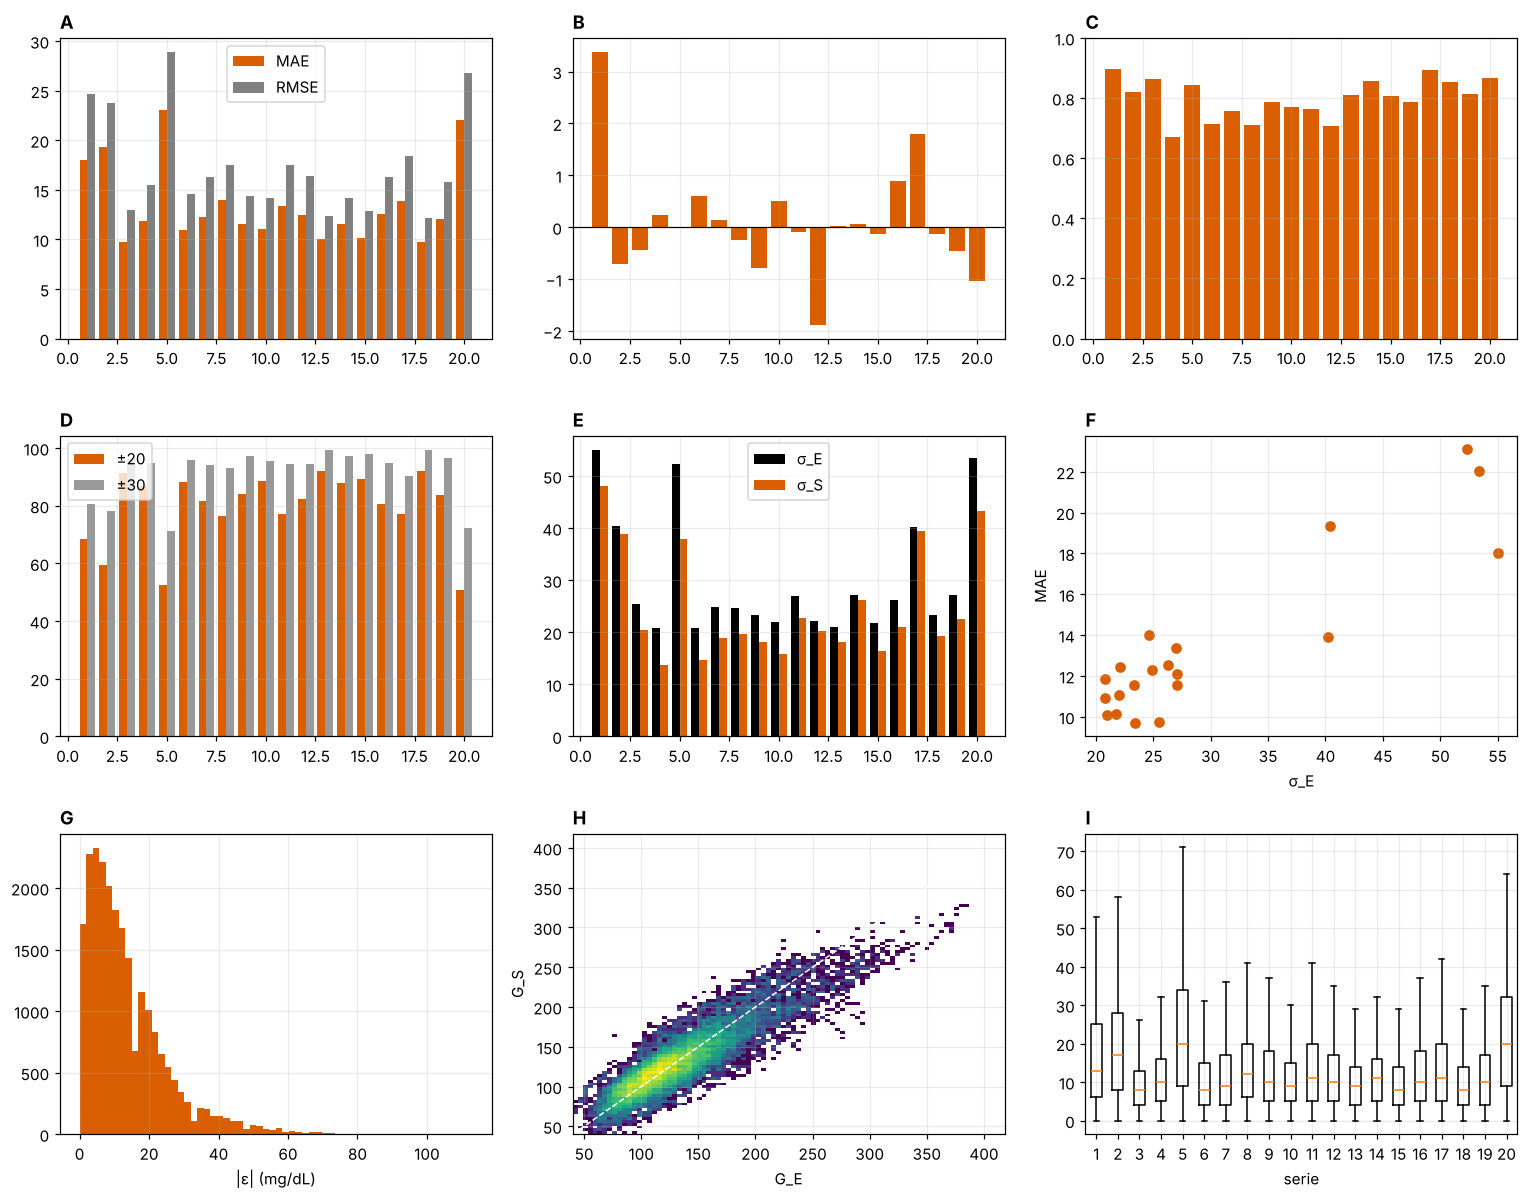

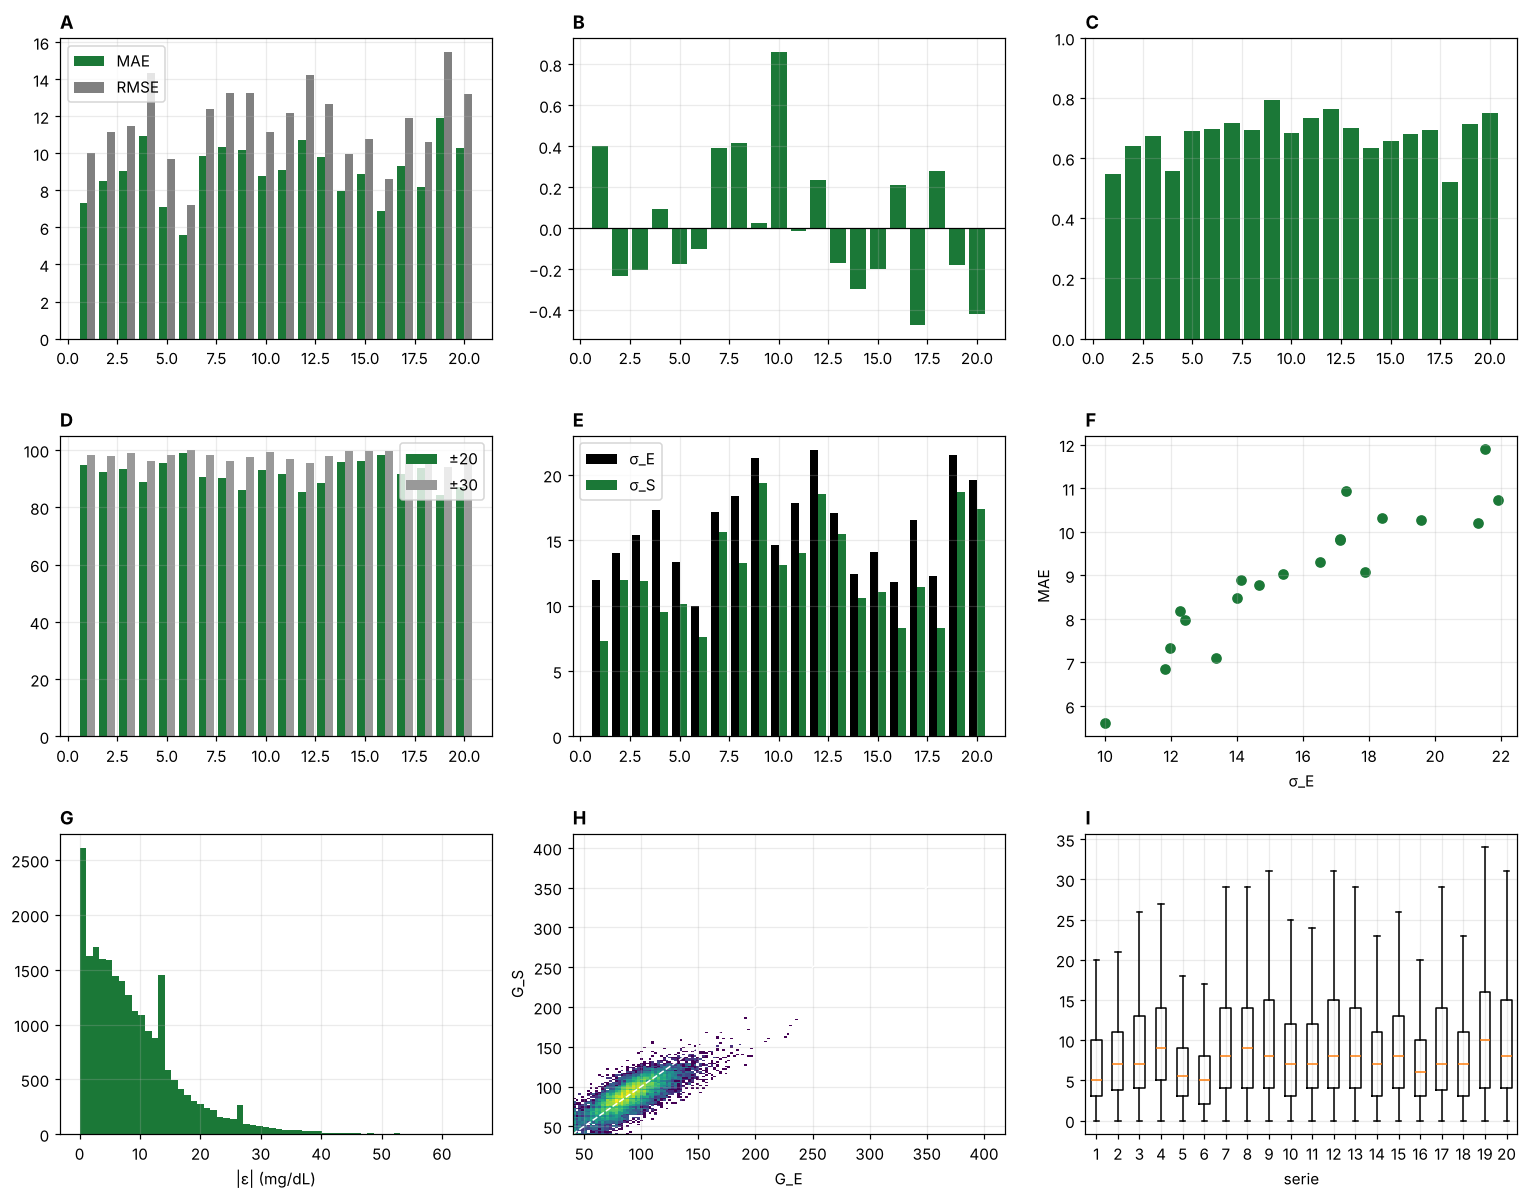

In [4]:
def figura_global(grupo, t, ruta):
    tt = t.iloc[:20]; E = np.concatenate([GE[grupo, i] for i in range(1, 21)]); S = np.concatenate([GS[grupo, i] for i in range(1, 21)])
    fig, ax = plt.subplots(3, 3, figsize=(14, 11)); ax = ax.ravel(); x = np.arange(1, 21); c = C[grupo]
    ax[0].bar(x - .2, tt.MAE, .4, color=c, label="MAE"); ax[0].bar(x + .2, tt.RMSE, .4, color="0.5", label="RMSE"); ax[0].legend()
    ax[1].bar(x, tt.ME, color=c); ax[1].axhline(0, color="k", lw=.8)
    ax[2].bar(x, tt.r, color=c); ax[2].set_ylim(0, 1)
    p30 = [error.metricas_error(GE[grupo, i], GS[grupo, i])["P_30"] for i in range(1, 21)]
    ax[3].bar(x - .2, tt.P_20, .4, color=c, label="±20"); ax[3].bar(x + .2, p30, .4, color="0.6", label="±30"); ax[3].legend()
    ax[4].bar(x - .2, tt.sigma_E, .4, color="k", label="σ_E"); ax[4].bar(x + .2, [GS[grupo, i].std() for i in x], .4, color=c, label="σ_S"); ax[4].legend()
    ax[5].scatter(tt.sigma_E, tt.MAE, color=c); ax[5].set(xlabel="σ_E", ylabel="MAE")
    ax[6].hist(np.abs(E - S), bins=60, color=c); ax[6].set_xlabel("|ε| (mg/dL)")
    ax[7].hist2d(E, S, bins=80, norm=LogNorm(), cmap="viridis"); ax[7].plot([40, 400], [40, 400], "w--", lw=1); ax[7].set(xlabel="G_E", ylabel="G_S")
    ax[8].boxplot([np.abs(GE[grupo, i] - GS[grupo, i]) for i in x], showfliers=False); ax[8].set_xlabel("serie")
    for a, l in zip(ax, "ABCDEFGHI"): a.set_title(l, loc="left", fontweight="bold")
    fig.tight_layout(); fig.savefig(ruta, dpi=200); plt.show()

figura_global("DBT2", t51, OUT / "figura_5_1_DBT2.png")
figura_global("NDBT2", t52, OUT / "figura_5_2_NDBT2.png")

## 3. Comparación descriptiva DBT2 vs NDBT2 (Fig. 5.3)

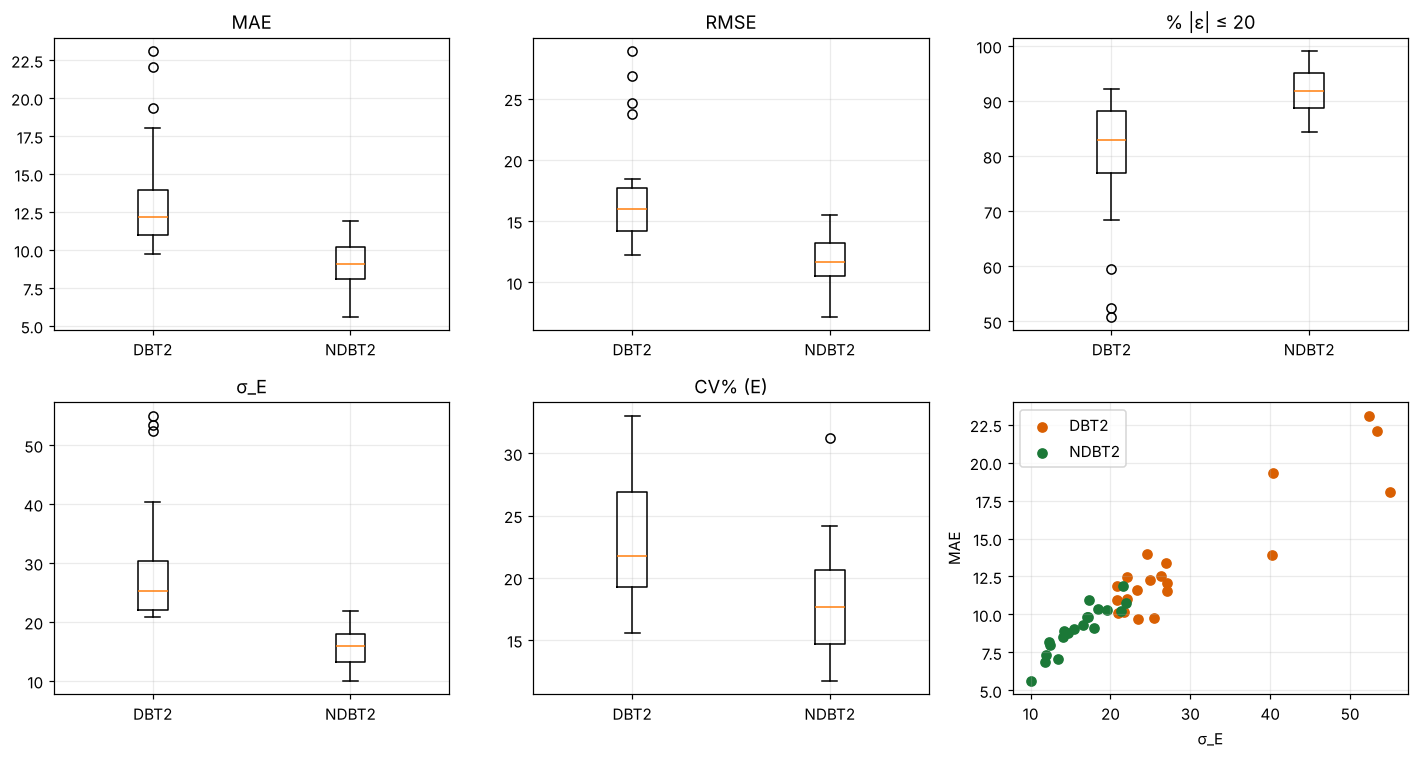

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(13, 7)); ax = ax.ravel()
for a, col, lab in zip(ax[:5], ["MAE", "RMSE", "P_20", "sigma_E", "CV_E"], ["MAE", "RMSE", "% |ε| ≤ 20", "σ_E", "CV% (E)"]):
    a.boxplot([t51[col][:20].astype(float), t52[col][:20].astype(float)], tick_labels=["DBT2", "NDBT2"]); a.set_title(lab)
for g, t in (("DBT2", t51), ("NDBT2", t52)):
    ax[5].scatter(t.sigma_E[:20], t.MAE[:20], color=C[g], label=g)
ax[5].set(xlabel="σ_E", ylabel="MAE"); ax[5].legend()
fig.tight_layout(); fig.savefig(OUT / "figura_5_3_comparacion.png", dpi=200); plt.show()

## 4. Compresión de amplitud y discrepancia de variabilidad (Sec. 5.10, Fig. 5.4)

DBT2: error medio decil inferior = -8.8 (G_E = 78); superior = +17.6 (G_E = 216); recorrido = 26.4; MAE decil superior |dG/dt| = 20.2 (|dG/dt| = 80 mg/dL/h)
   L1: media 4.0, mediana 4.3, rango 0.2–8.9; CV% 23.1 → 19.0
NDBT2: error medio decil inferior = -8.1 (G_E = 56); superior = +13.8 (G_E = 126); recorrido = 21.9; MAE decil superior |dG/dt| = 14.0 (|dG/dt| = 80 mg/dL/h)
   L1: media 4.5, mediana 3.9, rango 2.7–7.3; CV% 18.2 → 14.6
L1 DBT2 vs NDBT2 reales: Mann–Whitney p = 0.82


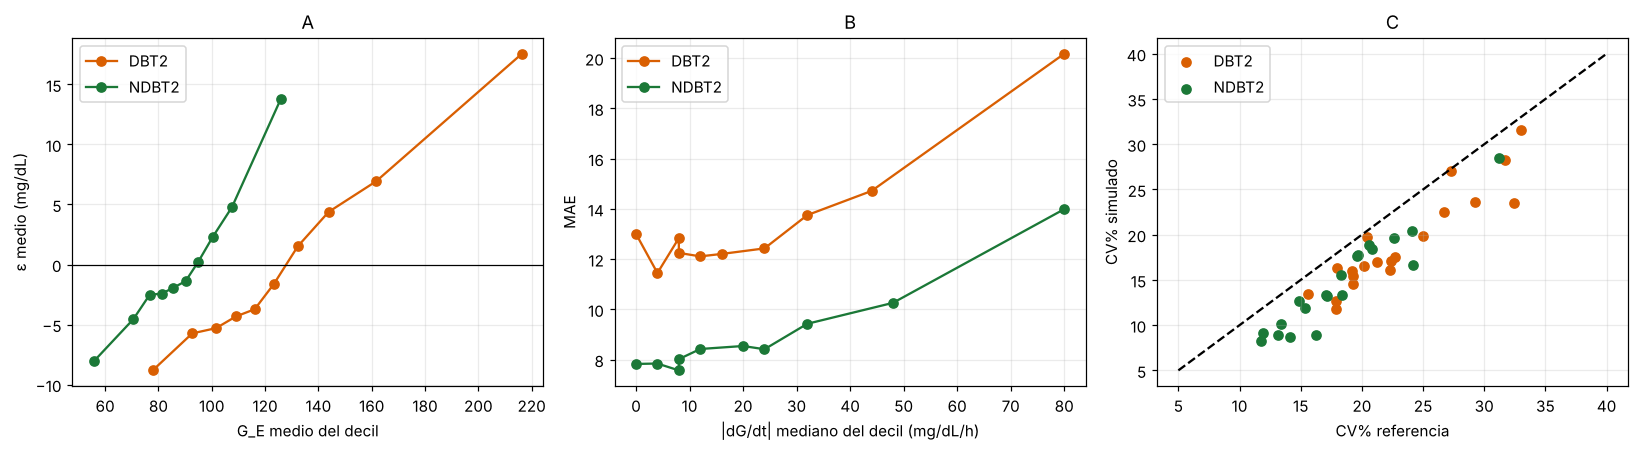

In [6]:
def deciles(grupo):
    E = np.concatenate([GE[grupo, i] for i in range(1, 21)]); S = np.concatenate([GS[grupo, i] for i in range(1, 21)])
    v = np.concatenate([np.r_[0, np.abs(np.diff(GE[grupo, i]))] * 4 for i in range(1, 21)])   # mg/dL por hora (diferencia hacia atrás)
    # deciles de igual tamaño; los empates se reparten por orden de aparición
    qe = pd.qcut(pd.Series(E).rank(method="first"), 10, labels=False); qv = pd.qcut(pd.Series(v).rank(method="first"), 10, labels=False)
    d1 = pd.DataFrame({"q": qe, "e": E - S, "GE": E}).groupby("q").mean()
    d2 = pd.DataFrame({"q": qv, "ae": np.abs(E - S), "v": v}).groupby("q").agg(ae=("ae", "mean"), v=("v", "median"))   # decil ubicado en su mediana
    return d1, d2

dec = {g: deciles(g) for g in ("DBT2", "NDBT2")}
for g in dec:
    d1, d2 = dec[g]
    print(f"{g}: error medio decil inferior = {d1.e.iloc[0]:+.1f} (G_E = {d1.GE.iloc[0]:.0f}); superior = {d1.e.iloc[-1]:+.1f} "
          f"(G_E = {d1.GE.iloc[-1]:.0f}); recorrido = {d1.e.iloc[-1] - d1.e.iloc[0]:.1f}; MAE decil superior |dG/dt| = "
          f"{d2.ae.iloc[-1]:.1f} (|dG/dt| = {d2.v.iloc[-1]:.0f} mg/dL/h)")
    t = t51 if g == "DBT2" else t52; L = t.L1[:20 if g == "DBT2" else 5].astype(float)
    print(f"   L1: media {L.mean():.1f}, mediana {L.median():.1f}, rango {L.min():.1f}–{L.max():.1f}; "
          f"CV% {t.CV_E[:20].mean():.1f} → {t.CV_S[:20].mean():.1f}")
print("L1 DBT2 vs NDBT2 reales: Mann–Whitney p =", round(stats.mannwhitneyu(t51.L1[:20].astype(float), t52.L1[:5].astype(float)).pvalue, 2))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for g in dec:
    d1, d2 = dec[g]
    ax[0].plot(d1.GE, d1.e, "o-", color=C[g], label=g); ax[1].plot(d2.v, d2.ae, "o-", color=C[g], label=g)
    t = t51 if g == "DBT2" else t52; ax[2].scatter(t.CV_E[:20], t.CV_S[:20], color=C[g], label=g)
ax[0].axhline(0, color="k", lw=.8); ax[0].set(xlabel="G_E medio del decil", ylabel="ε medio (mg/dL)", title="A")
ax[1].set(xlabel="|dG/dt| mediano del decil (mg/dL/h)", ylabel="MAE", title="B"); ax[2].plot([5, 40], [5, 40], "k--")
ax[2].set(xlabel="CV% referencia", ylabel="CV% simulado", title="C")
for a in ax: a.legend()
fig.tight_layout(); fig.savefig(OUT / "figura_5_4_amplitud.png", dpi=200); plt.show()

## 5. Resolución diaria e intradiaria (Sec. 5.11, Tablas 5.3–5.4, Figs. 5.5–5.6)

In [7]:
def diario(grupo):
    filas, corr = [], []
    for i in range(1, 21):
        md = error.mae_diario(GE[grupo, i], GS[grupo, i]); cv = error.cv_diario(GE[grupo, i])
        r = np.corrcoef(cv, md)[0, 1]; corr.append(r)
        md1 = np.round(md, 1)                       # la tesis calcula Δ sobre los valores redondeados a 0,1
        filas.append({"S": i, **{f"D{d+1}": md[d] for d in range(12)}, "Δ": md1.max() - md1.min(), "r_d": r})
    return pd.DataFrame(filas)

t53, t54 = diario("DBT2"), diario("NDBT2")
t53.round(1).to_csv(OUT / "tabla_5_3_mae_diario_DBT2.csv", index=False); t54.round(1).to_csv(OUT / "tabla_5_4_mae_diario_NDBT2.csv", index=False)
for g, t, ids in (("DBT2", t53, slice(0, 20)), ("NDBT2 reales", t54, slice(0, 5))):
    M = t.iloc[ids, 1:13].to_numpy(float); r = t.r_d.iloc[ids]
    print(f"{g}: MAE diario {M.min():.1f}–{M.max():.1f}; Δ medio {t['Δ'].iloc[ids].mean():.1f} "
          f"(rango {t['Δ'].iloc[ids].min():.1f}–{t['Δ'].iloc[ids].max():.1f}); max/min medio {np.mean(M.max(1) / M.min(1)):.2f}; "
          f"DE intra {np.mean(M.std(1, ddof=1)):.2f} vs entre {M.mean(1).std(ddof=1):.2f}; r_d media {r.mean():.3f}, "
          f"mediana {r.median():.3f}, positivas {np.sum(r > 0)}/{len(r)}; Wilcoxon p = {stats.wilcoxon(r).pvalue:.1e}")
display(t53.round(1))

DBT2: MAE diario 5.2–37.6; Δ medio 15.4 (rango 7.8–29.6); max/min medio 3.19; DE intra 4.56 vs entre 3.98; r_d media 0.437, mediana 0.466, positivas 19/20; Wilcoxon p = 9.5e-06
NDBT2 reales: MAE diario 4.6–18.8; Δ medio 7.8 (rango 5.2–11.3); max/min medio 2.40; DE intra 2.25 vs entre 1.55; r_d media 0.718, mediana 0.793, positivas 5/5; Wilcoxon p = 6.2e-02


,S,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12,Δ,r_d
0,1,21.3,24.3,24.4,30.6,9.2,25.5,13.1,24.7,16.1,9.9,9.4,8.0,22.6,0.8
1,2,20.6,8.0,15.9,37.6,17.6,25.1,12.0,19.2,20.9,27.2,14.4,13.7,29.6,-0.2
2,3,5.2,6.2,14.0,6.1,6.0,6.9,13.9,25.3,6.7,6.4,13.3,7.1,20.1,0.7
3,4,15.4,15.8,11.6,14.7,9.3,10.8,8.1,7.6,12.4,12.6,12.0,12.2,8.2,0.7
4,5,24.1,25.4,18.5,29.0,31.0,11.5,26.2,24.2,13.1,24.3,19.7,30.1,19.5,0.6
5,6,13.7,13.7,10.5,13.6,11.8,13.3,9.8,5.8,7.8,10.4,11.9,8.9,7.9,0.3
6,7,18.2,10.7,7.1,8.2,12.3,10.2,13.0,10.8,9.5,23.1,10.9,13.4,16.0,0.4
7,8,13.8,13.2,13.2,19.2,14.8,13.7,13.7,13.4,10.0,12.6,13.4,17.1,9.2,0.3
8,9,10.0,9.4,7.7,20.0,9.3,13.3,5.7,8.0,9.5,16.3,14.4,15.1,14.3,0.5
9,10,8.9,7.4,15.2,13.2,8.9,9.1,10.0,11.6,11.7,18.8,9.1,8.6,11.4,0.5


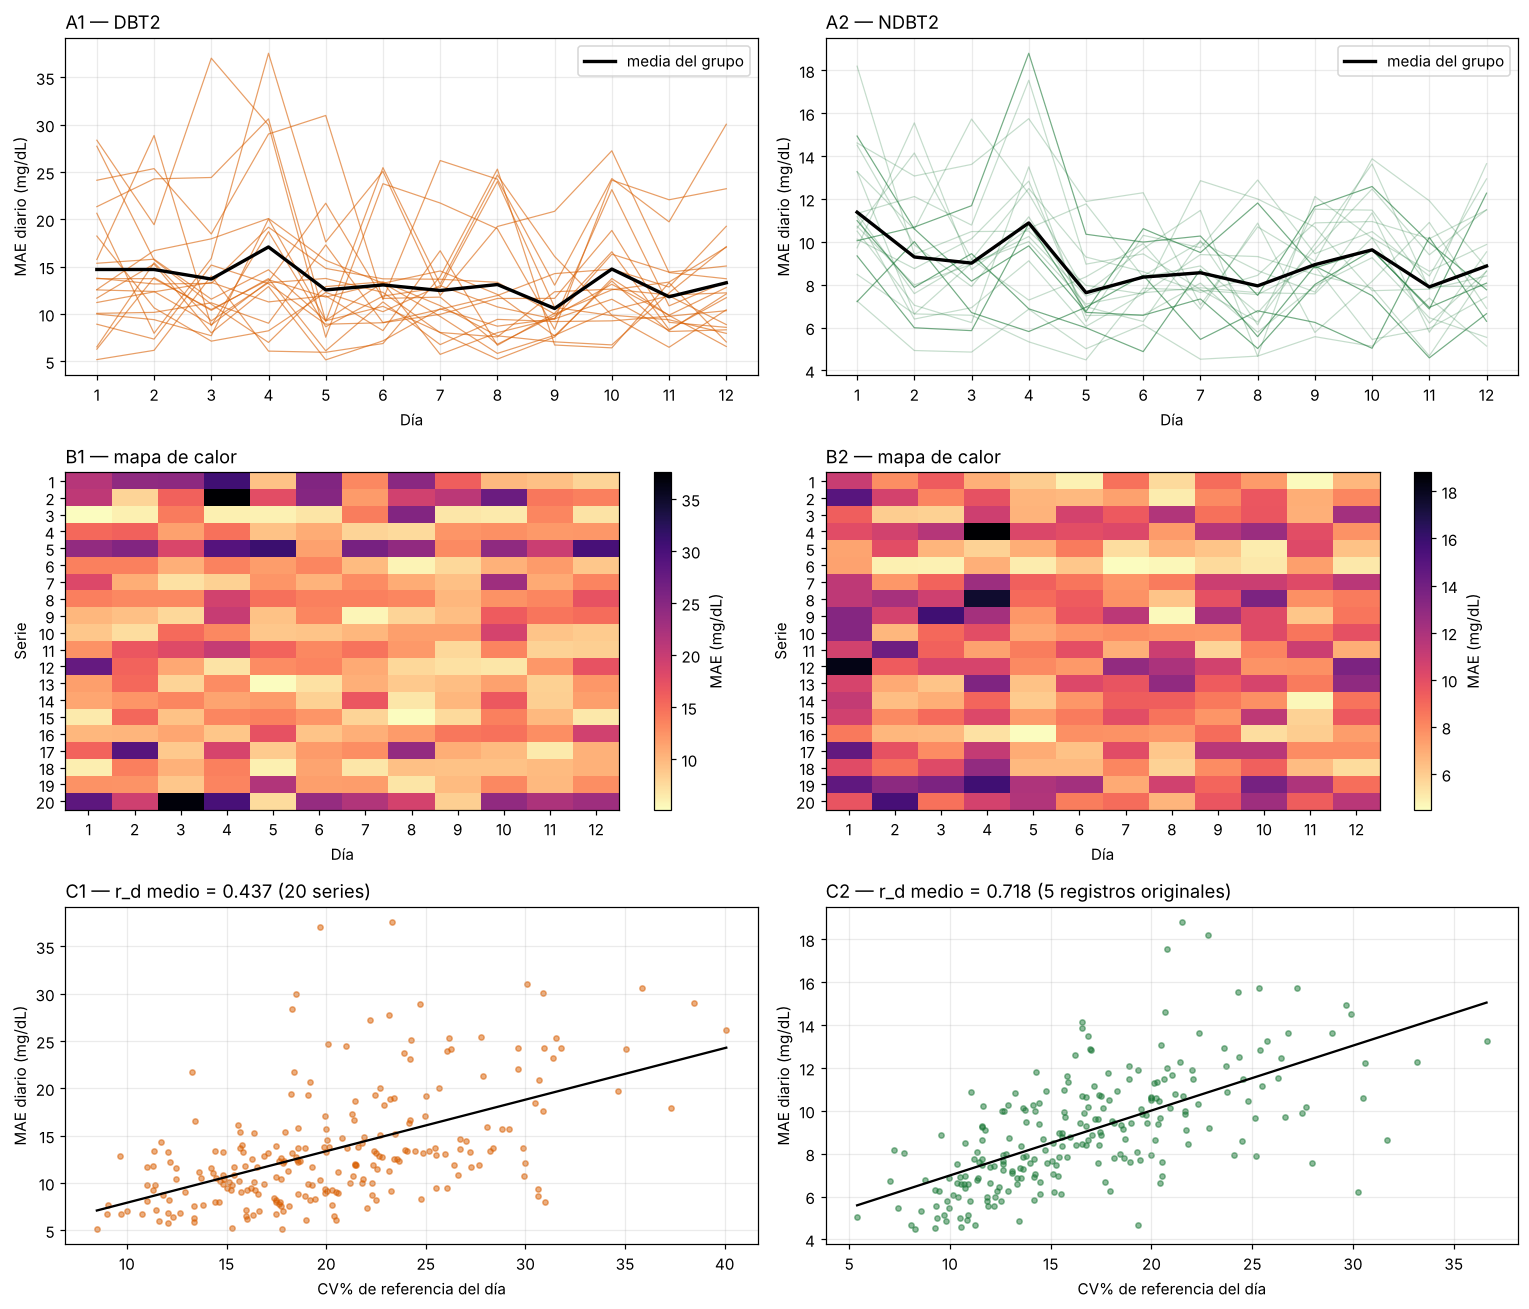

In [8]:
# Figura 5.5 — resolución diaria del error
fig, ax = plt.subplots(3, 2, figsize=(14, 12))
for col, (g, t, n_inf) in enumerate((("DBT2", t53, 20), ("NDBT2", t54, 5))):
    M = t.iloc[:, 1:13].to_numpy(float); dias = np.arange(1, 13)
    for k in range(20):
        ax[0, col].plot(dias, M[k], color=C[g], alpha=.6 if k < n_inf else .25, lw=.8)
    ax[0, col].plot(dias, M.mean(0), "k", lw=2.2, label="media del grupo")
    ax[0, col].set(xlabel="Día", ylabel="MAE diario (mg/dL)", xticks=dias); ax[0, col].legend(loc="upper right")
    ax[0, col].set_title(f"A{col+1} — {g}", loc="left")
    im = ax[1, col].imshow(M, aspect="auto", cmap="magma_r", extent=[.5, 12.5, 20.5, .5])
    ax[1, col].set(xlabel="Día", ylabel="Serie", xticks=dias, yticks=range(1, 21)); ax[1, col].grid(False)
    fig.colorbar(im, ax=ax[1, col], label="MAE (mg/dL)"); ax[1, col].set_title(f"B{col+1} — mapa de calor", loc="left")
    cv = np.array([error.cv_diario(GE[g, i]) for i in range(1, 21)])
    ax[2, col].scatter(cv.ravel(), M.ravel(), s=12, color=C[g], alpha=.5)
    pend, ord_ = np.polyfit(cv.ravel(), M.ravel(), 1); xx = np.linspace(cv.min(), cv.max(), 50)
    ax[2, col].plot(xx, pend * xx + ord_, "k", lw=1.5)
    r_media = t.r_d.iloc[:n_inf].mean()
    etiqueta = "series" if n_inf == 20 else "registros originales"
    ax[2, col].set(xlabel="CV% de referencia del día", ylabel="MAE diario (mg/dL)")
    ax[2, col].set_title(f"C{col+1} — r_d medio = {r_media:.3f} ({n_inf} {etiqueta})", loc="left")
fig.tight_layout(); fig.savefig(OUT / "figura_5_5_resolucion_diaria.png", dpi=200); plt.show()

DBT2: perfil 10.7–16.0 mg/dL; máximo a las 12:45; MAE 03–08 h = 13.7, resto = 13.4
NDBT2: perfil 6.5–11.8 mg/dL; máximo a las 17:45; MAE 03–08 h = 8.4, resto = 9.2


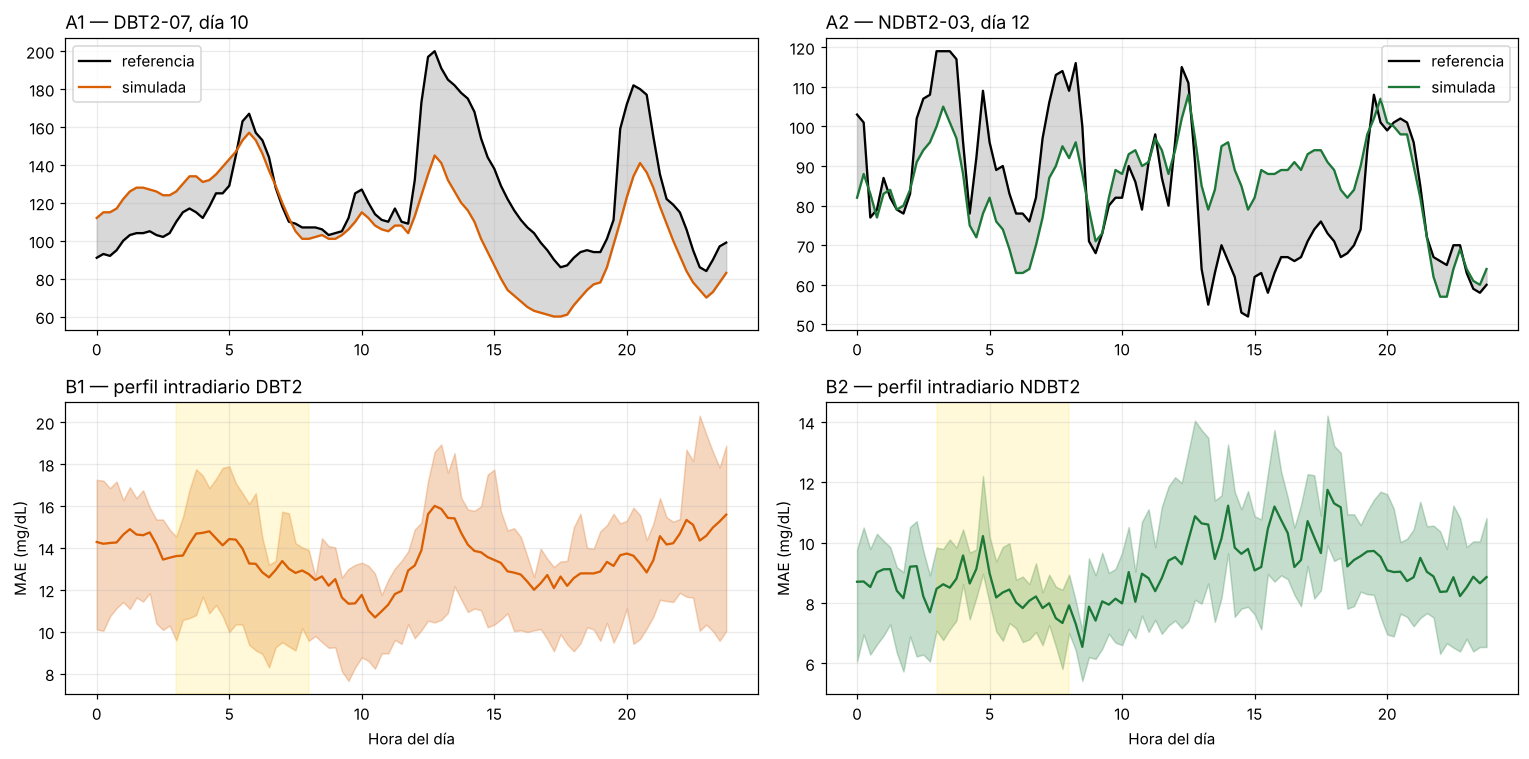

In [9]:
def perfil(grupo):
    return np.array([np.abs(GE[grupo, i] - GS[grupo, i]).reshape(12, 96).mean(0) for i in range(1, 21)])

pf = {g: perfil(g) for g in ("DBT2", "NDBT2")}
h = np.arange(96) / 4
fig, ax = plt.subplots(2, 2, figsize=(14, 7))
for col, (g, i, d) in enumerate([("DBT2", 7, 10), ("NDBT2", 3, 12)]):
    sl = slice(96 * (d - 1), 96 * d); e, s = GE[g, i][sl], GS[g, i][sl]
    ax[0, col].plot(h, e, "k", label="referencia"); ax[0, col].plot(h, s, color=C[g], label="simulada")
    ax[0, col].fill_between(h, e, s, color="0.7", alpha=.5); ax[0, col].set_title(f"A{col+1} — {g}-{i:02d}, día {d}", loc="left"); ax[0, col].legend()
    P = pf[g]; ax[1, col].plot(h, P.mean(0), color=C[g]); ax[1, col].fill_between(h, *np.percentile(P, [25, 75], axis=0), color=C[g], alpha=.25)
    ax[1, col].axvspan(3, 8, color="gold", alpha=.15); ax[1, col].set(xlabel="Hora del día", ylabel="MAE (mg/dL)")
    ax[1, col].set_title(f"B{col+1} — perfil intradiario {g}", loc="left")
    m = P.mean(0); alba = (h >= 3) & (h < 8)
    print(f"{g}: perfil {m.min():.1f}–{m.max():.1f} mg/dL; máximo a las {int(h[m.argmax()])}:{int(60*(h[m.argmax()]%1)):02d}; "
          f"MAE 03–08 h = {m[alba].mean():.1f}, resto = {m[~alba].mean():.1f}")
fig.tight_layout(); fig.savefig(OUT / "figura_5_6_resolucion_15min.png", dpi=200); plt.show()

## 6. Grilla de error de Clarke (Sec. 5.12, Fig. 5.7)

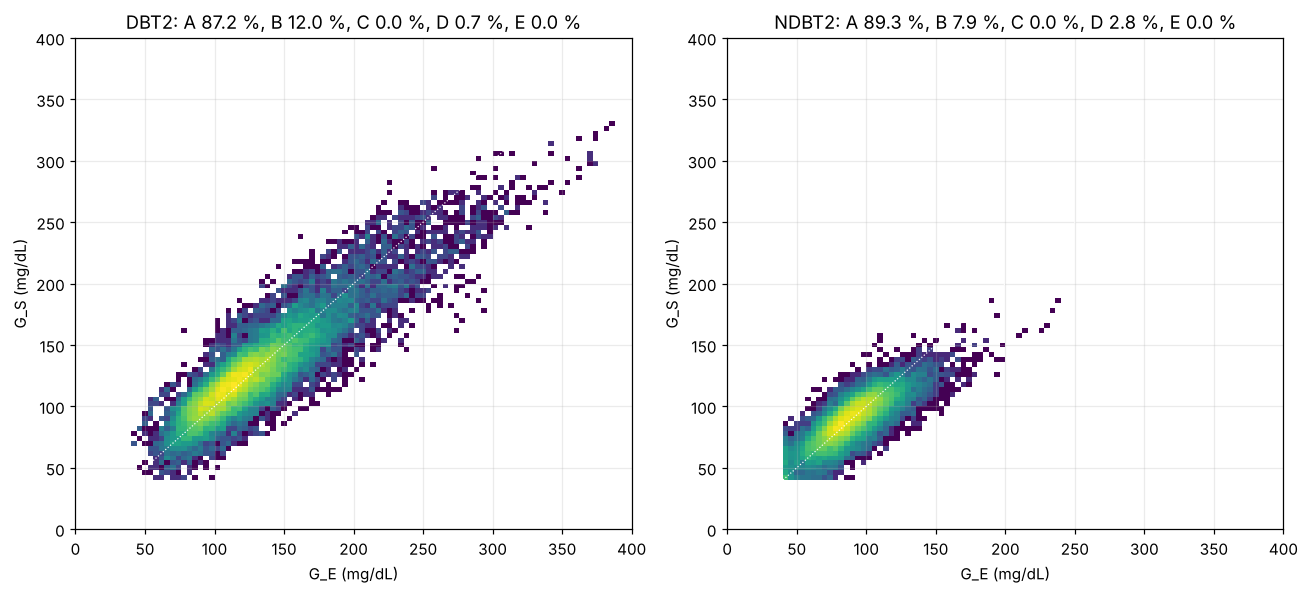

,A,B,C,D,E
DBT2,87.2,12.0,0.0,0.7,0.0
NDBT2,89.3,7.9,0.0,2.8,0.0


In [10]:
clarke = {}
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
for a, g in zip(ax, ("DBT2", "NDBT2")):
    E = np.concatenate([GE[g, i] for i in range(1, 21)]); S = np.concatenate([GS[g, i] for i in range(1, 21)])
    clarke[g] = error.porcentajes_clarke(E, S)
    a.hist2d(E, S, bins=100, range=[[0, 400], [0, 400]], norm=LogNorm(), cmap="viridis")
    a.plot([0, 400], [0, 400], "w:", lw=.8)
    a.set(xlabel="G_E (mg/dL)", ylabel="G_S (mg/dL)", title=f"{g}: " + ", ".join(f"{k} {v:.1f} %" for k, v in clarke[g].items()))
fig.tight_layout(); fig.savefig(OUT / "figura_5_7_clarke.png", dpi=200); plt.show()
pd.DataFrame(clarke).T.round(1)

## 7. Figuras 5.1–5.3 con el script original del capítulo
`originales/cap5_figuras/capitulo_5_figuras.py` genera las Figuras 5.1–5.3 con el diseño
de la tesis (paneles A–I). Se ejecuta en modo «real»: lee G_E y G_S de cada serie y
recalcula las métricas, que coinciden con las filas «Global» de las Tablas 5.1 y 5.2.
Las figuras quedan en `resultados/cap5/original/` (PNG y PDF vectorial).

Modo de datos: real
N por grupo  : 20 × 1152 = 23040 puntos
{'DBT2': (20, (1152,)), 'NDBT2': (20, (1152,))}
Verificación global (recalculado | publicado)
  DBT2   MAE  13.5 |   13   RMSE  17.9 |   18   r 0.892 | 0.892   beta 0.797 | 0.797   P95  37.0 |   37   <=20   80% |  80%
  NDBT2  MAE   9.0 |    9   RMSE  11.9 |   12   r 0.799 | 0.799   beta 0.698 | 0.698   P95  24.0 |   25   <=20   92% |  91%
  ✓ figura_5_1_DBT2.png
  ✓ figura_5_1_DBT2.pdf
  ✓ figura_5_2_NDBT2.png
  ✓ figura_5_2_NDBT2.pdf
  ✓ figura_5_3_comparativa.png
  ✓ figura_5_3_comparativa.pdf
        ME   MAE  RMSE   P95  pct20      r   beta
DBT2   0.0  13.0  18.0  37.0   80.0  0.892  0.797
NDBT2  0.0   9.0  12.0  25.0   91.0  0.799  0.698

Cocientes DBT2 / NDBT2:
MAE     1.44
RMSE    1.50
P95     1.48
  ✓ tabla_5_1_DBT2.csv
  ✓ tabla_5_2_NDBT2.csv


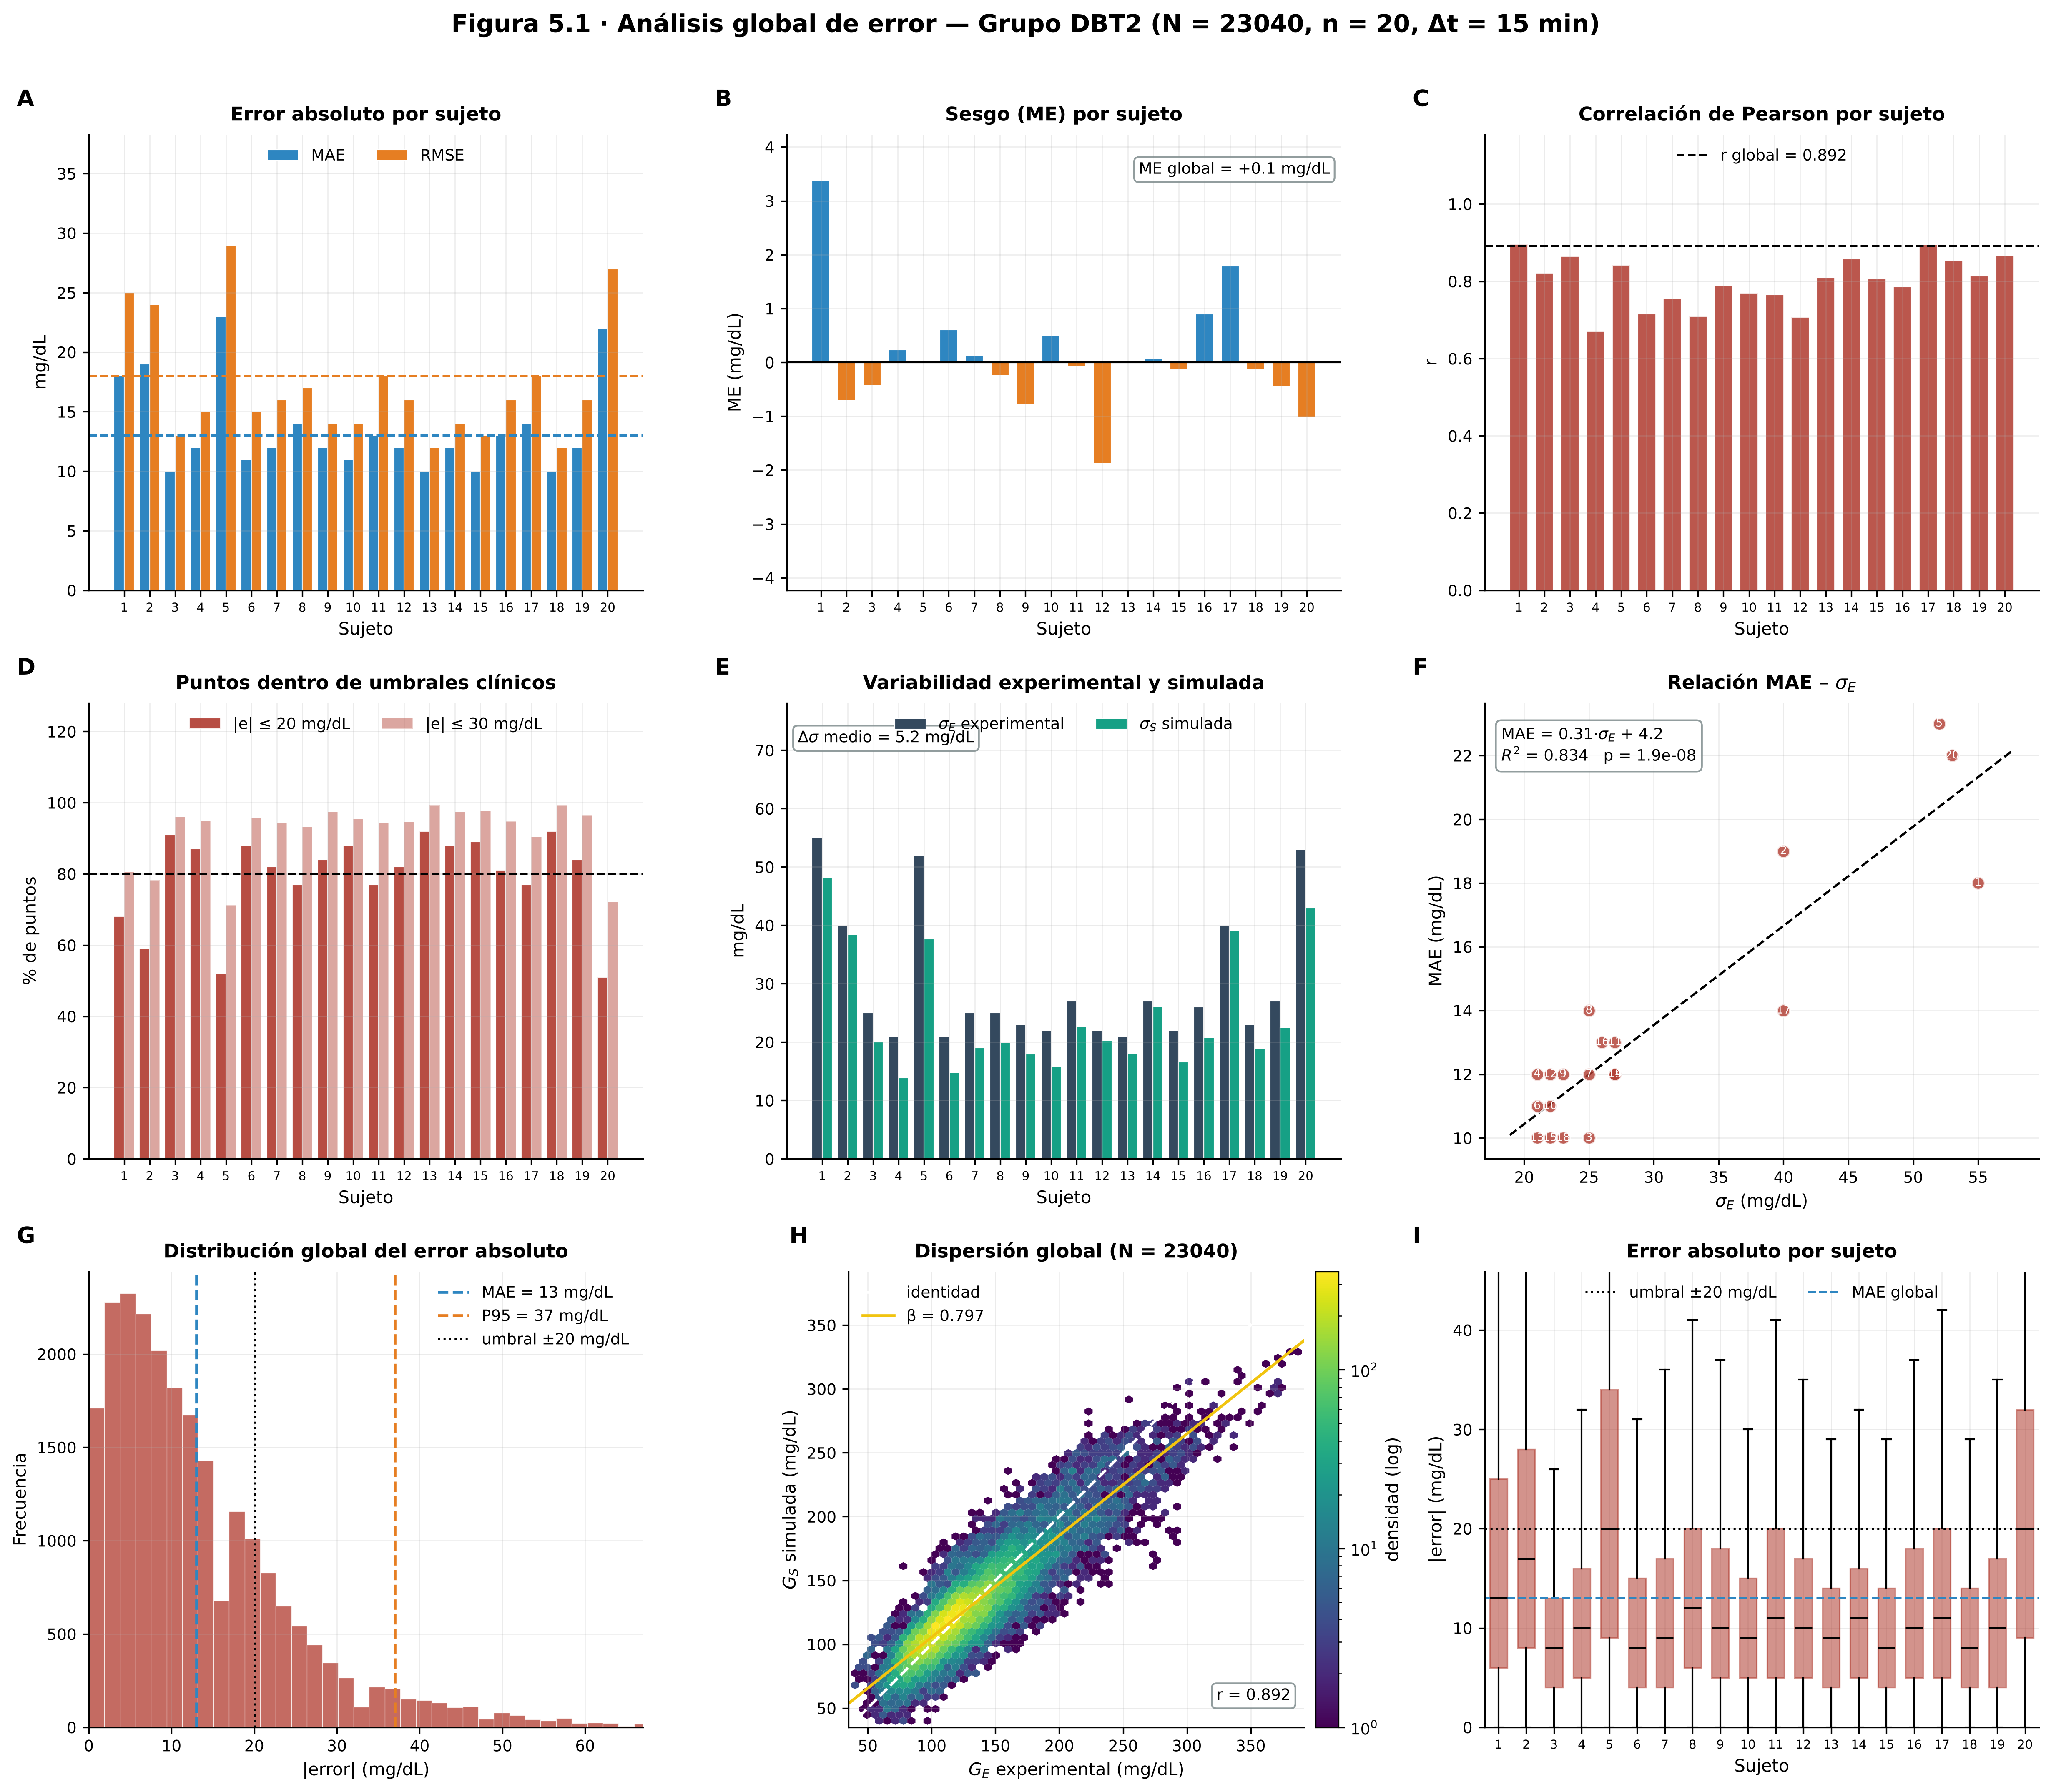

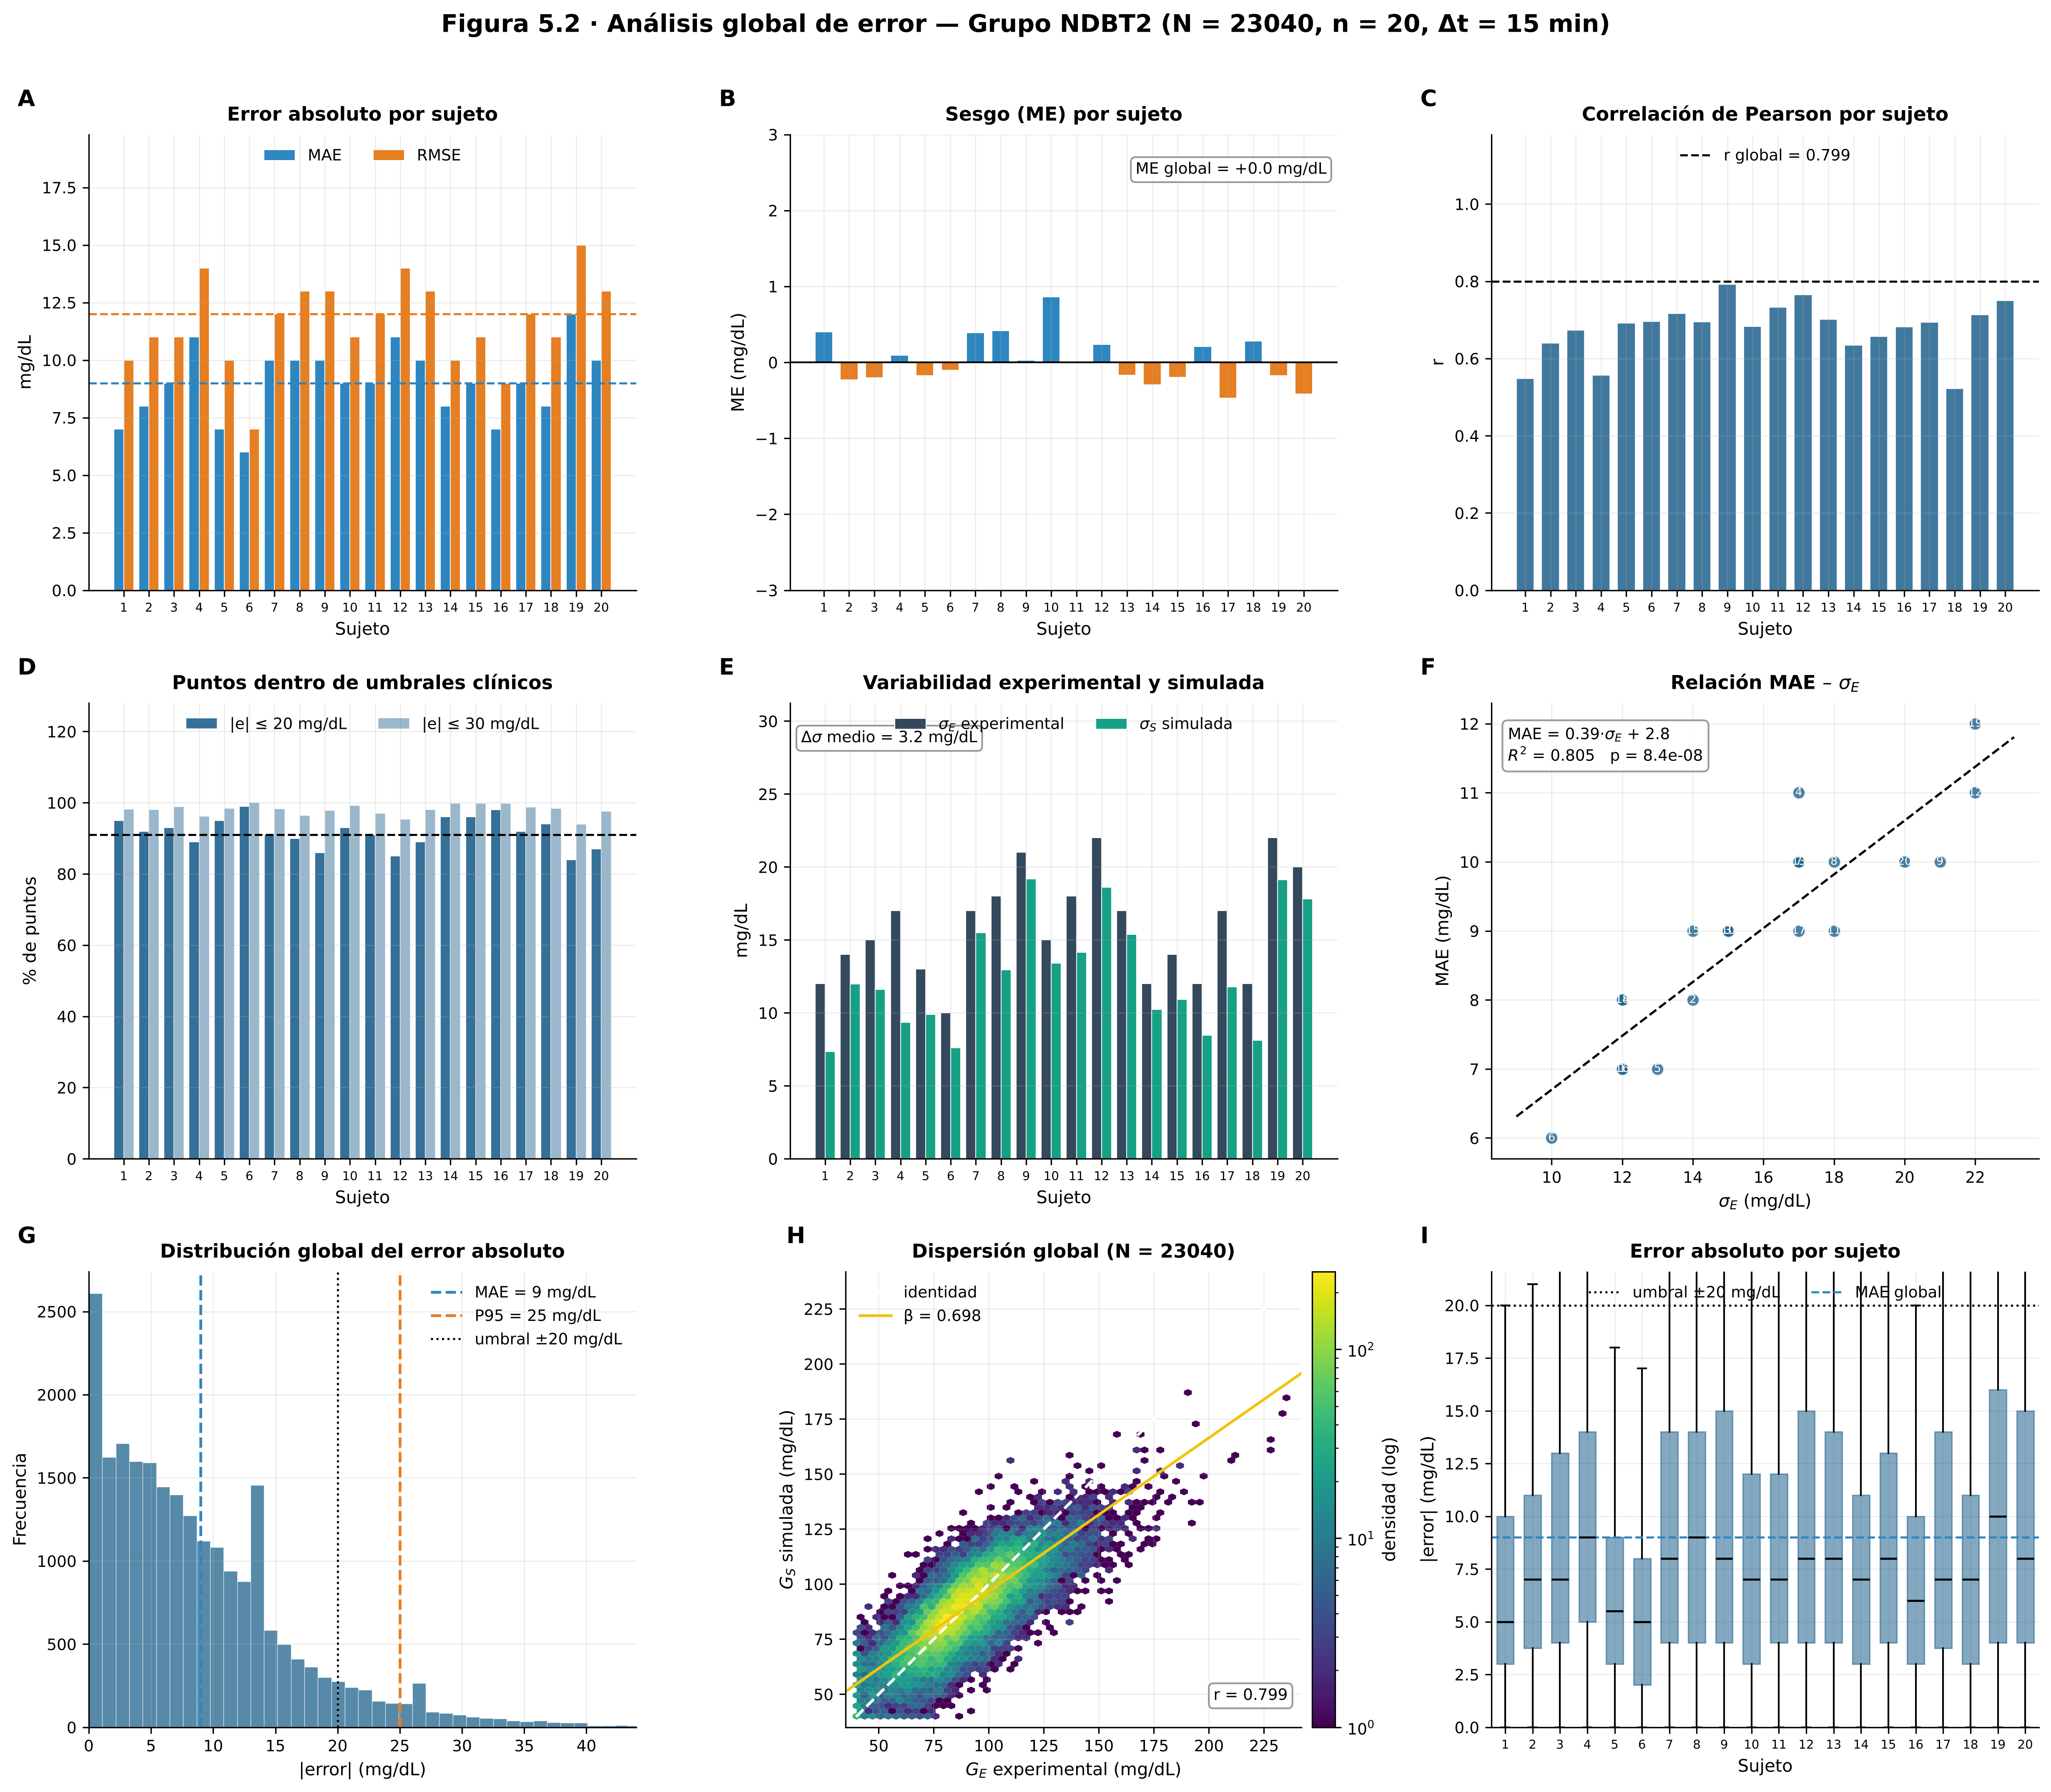

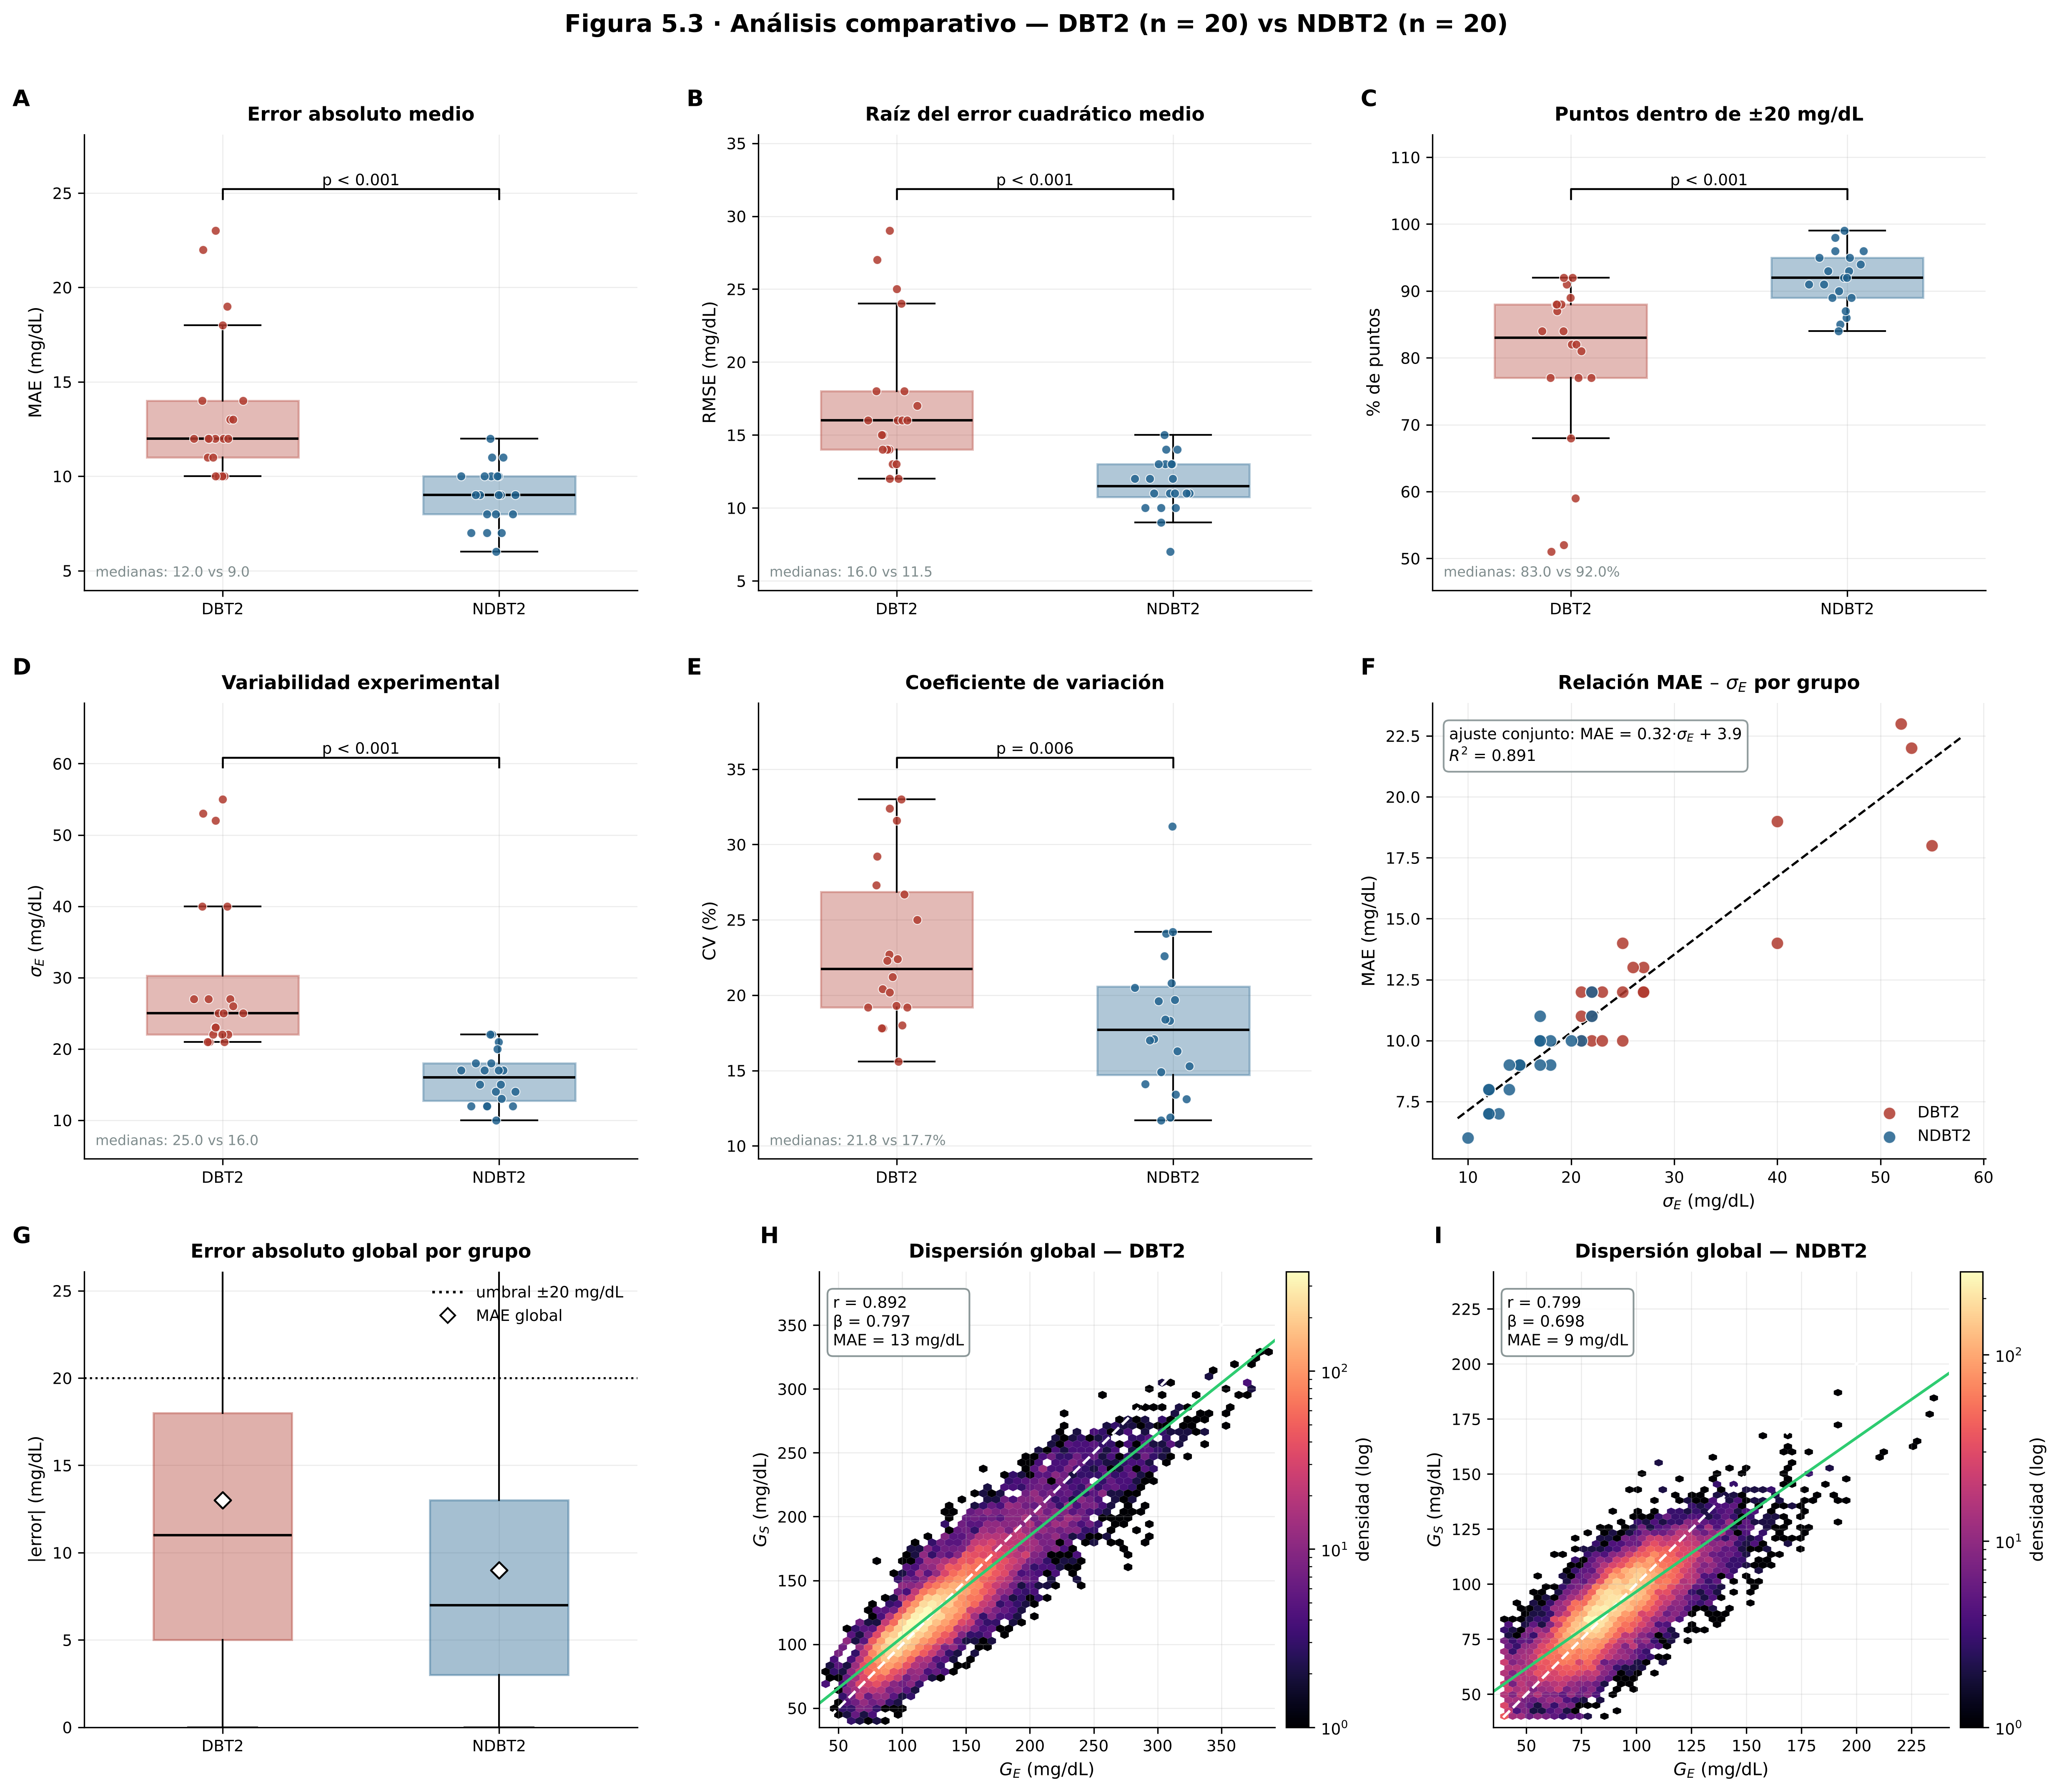

In [11]:
sys.path.insert(0, str(Path.cwd().parent / "originales" / "cap5_figuras" if Path.cwd().name == "notebooks" else Path.cwd() / "originales" / "cap5_figuras"))
import reproducir as orig5
SAL5 = orig5.ejecutar(OUT / "original")
from IPython.display import Image, display
for f in ("figura_5_1_DBT2.png", "figura_5_2_NDBT2.png", "figura_5_3_comparativa.png"):
    display(Image(filename=str(SAL5 / f), width=900))

## Verificación contra la tesis

In [12]:
def fila(dato, tesis, obtenido, dec, tol=0.0):
    o = round(float(obtenido), dec)
    ok = "✔" if abs(o - tesis) < 1e-9 else ("≈" if abs(o - tesis) <= tol + 1e-9 else "✘")
    return dict(Dato=dato, Tesis=tesis, Reproducido=o, Coincide=ok)

TESIS_5 = {'5.1': {1: (174.0, 55.0, 31.7, 28.3, 3.4, 18.0, 25.0, 0.896, 0.785, 52.0, 68.0, 0.294, 36.8), 2: (122.0, 40.0, 33.0, 31.6, 1.5, 19.0, 24.0, 0.821, 0.789, 46.0, 59.0, 0.312, 86.4), 3: (120.0, 26.0, 21.2, 17.0, 4.2, 10.0, 13.0, 0.864, 0.694, 26.0, 91.0, 0.101, 19.6), 4: (117.0, 21.0, 17.9, 11.8, 6.0, 12.0, 15.0, 0.67, 0.443, 31.0, 87.0, 0.354, 33.9), 5: (161.0, 52.0, 32.4, 23.5, 8.9, 23.0, 29.0, 0.842, 0.61, 55.0, 52.0, 0.19, 67.1), 6: (117.0, 21.0, 17.9, 12.7, 5.2, 11.0, 15.0, 0.715, 0.505, 28.0, 88.0, 0.16, 37.6), 7: (111.0, 25.0, 22.4, 17.1, 5.3, 12.0, 16.0, 0.755, 0.575, 32.0, 82.0, 0.193, 47.1), 8: (98.0, 25.0, 25.0, 19.9, 5.1, 14.0, 17.0, 0.709, 0.566, 33.0, 77.0, 0.667, 48.9), 9: (103.0, 23.0, 22.7, 17.5, 5.1, 12.0, 14.0, 0.789, 0.615, 27.0, 84.0, 0.115, 58.5), 10: (99.0, 22.0, 22.3, 16.1, 6.2, 11.0, 14.0, 0.769, 0.553, 29.0, 88.0, 0.174, 19.6), 11: (101.0, 27.0, 26.7, 22.5, 4.3, 13.0, 18.0, 0.765, 0.643, 31.0, 77.0, 0.551, 16.2), 12: (123.0, 22.0, 18.0, 16.3, 1.7, 12.0, 16.0, 0.707, 0.65, 31.0, 82.0, 0.576, 41.7), 13: (135.0, 21.0, 15.6, 13.4, 2.1, 10.0, 12.0, 0.809, 0.698, 23.0, 92.0, 0.366, 86.7), 14: (133.0, 27.0, 20.4, 19.7, 0.7, 12.0, 14.0, 0.858, 0.83, 26.0, 88.0, 0.183, 18.3), 15: (113.0, 22.0, 19.3, 14.5, 4.8, 10.0, 13.0, 0.806, 0.607, 26.0, 89.0, 0.324, 31.3), 16: (136.0, 26.0, 19.2, 15.5, 3.8, 13.0, 16.0, 0.786, 0.629, 31.0, 81.0, 0.302, 39.9), 17: (147.0, 40.0, 27.3, 27.1, 0.2, 14.0, 18.0, 0.894, 0.876, 38.0, 77.0, 0.264, 80.0), 18: (116.0, 23.0, 20.2, 16.6, 3.6, 10.0, 12.0, 0.854, 0.701, 23.0, 92.0, 0.101, 22.9), 19: (141.0, 27.0, 19.2, 15.9, 3.2, 12.0, 16.0, 0.814, 0.678, 28.0, 84.0, 0.101, 34.9), 20: (183.0, 53.0, 29.2, 23.6, 5.6, 22.0, 27.0, 0.867, 0.704, 51.0, 51.0, 0.342, 20.3)}, '5.2': {18: (93.0, 12.0, 13.1, 8.9, 4.2, 8.0, 11.0, 0.522, 0.353, 22.0, 94.0, 0.505, 23.7), 19: (95.0, 22.0, 22.7, 19.7, 3.0, 12.0, 15.0, 0.713, 0.62, 32.0, 84.0, 0.171, 18.1), 20: (94.0, 20.0, 20.8, 18.4, 2.4, 10.0, 13.0, 0.75, 0.668, 27.0, 87.0, 0.129, 20.5), 1: (85.0, 12.0, 14.1, 8.7, 5.5, 7.0, 10.0, 0.548, 0.335, 21.0, 95.0, 0.25, 69.7), 2: (77.0, 14.0, 18.3, 15.6, 2.7, 8.0, 11.0, 0.64, 0.548, 24.0, 92.0, 0.459, 20.0), 3: (90.0, 15.0, 17.1, 13.2, 3.9, 9.0, 11.0, 0.673, 0.521, 22.0, 93.0, 0.476, 18.9), 4: (106.0, 17.0, 16.3, 8.9, 7.3, 11.0, 14.0, 0.557, 0.306, 28.0, 89.0, 0.45, 15.0), 5: (100.0, 13.0, 13.4, 10.1, 3.2, 7.0, 10.0, 0.692, 0.526, 19.0, 95.0, 0.238, 87.3), 6: (84.0, 10.0, 12.0, 9.1, 2.9, 6.0, 7.0, 0.696, 0.53, 14.0, 99.0, 0.295, 17.5), 7: (83.0, 17.0, 20.5, 18.8, 1.7, 10.0, 12.0, 0.716, 0.653, 25.0, 91.0, 0.391, 15.2), 8: (100.0, 18.0, 18.4, 13.3, 5.1, 10.0, 13.0, 0.695, 0.5, 27.0, 90.0, 0.101, 16.9), 9: (68.0, 21.0, 31.2, 28.5, 2.7, 10.0, 13.0, 0.792, 0.723, 26.0, 86.0, 0.129, 69.9), 10: (75.0, 15.0, 19.7, 17.8, 1.9, 9.0, 11.0, 0.683, 0.61, 23.0, 93.0, 0.409, 15.2), 11: (105.0, 18.0, 17.0, 13.4, 3.7, 9.0, 12.0, 0.733, 0.576, 25.0, 91.0, 0.185, 32.1), 12: (91.0, 22.0, 24.1, 20.5, 3.7, 11.0, 14.0, 0.765, 0.647, 30.0, 85.0, 0.159, 16.5), 13: (87.0, 17.0, 19.6, 17.7, 1.9, 10.0, 13.0, 0.701, 0.634, 25.0, 89.0, 0.394, 17.0), 14: (84.0, 12.0, 14.9, 12.6, 2.2, 8.0, 10.0, 0.634, 0.541, 20.0, 96.0, 0.52, 15.1), 15: (92.0, 14.0, 15.3, 11.9, 3.4, 9.0, 11.0, 0.657, 0.512, 20.0, 96.0, 0.548, 19.0), 16: (101.0, 12.0, 11.7, 8.3, 3.4, 7.0, 9.0, 0.682, 0.481, 17.0, 98.0, 0.29, 15.0), 17: (68.0, 17.0, 24.2, 16.7, 7.5, 9.0, 12.0, 0.694, 0.481, 24.0, 92.0, 0.307, 53.8)}, '5.3': {1: (21.0, 24.0, 24.0, 31.0, 9.0, 26.0, 13.0, 25.0, 16.0, 10.0, 9.0, 8.0, 22.6, 0.8), 2: (21.0, 8.0, 16.0, 38.0, 18.0, 25.0, 12.0, 19.0, 21.0, 27.0, 14.0, 14.0, 29.6, -0.24), 3: (5.0, 6.0, 14.0, 6.0, 6.0, 7.0, 14.0, 25.0, 7.0, 6.0, 13.0, 7.0, 20.1, 0.72), 4: (15.0, 16.0, 12.0, 15.0, 9.0, 11.0, 8.0, 8.0, 12.0, 13.0, 12.0, 12.0, 8.2, 0.66), 5: (24.0, 25.0, 19.0, 29.0, 31.0, 12.0, 26.0, 24.0, 13.0, 24.0, 20.0, 30.0, 19.5, 0.55), 6: (14.0, 14.0, 11.0, 14.0, 12.0, 13.0, 10.0, 6.0, 8.0, 10.0, 12.0, 9.0, 7.9, 0.34), 7: (18.0, 11.0, 7.0, 8.0, 12.0, 10.0, 13.0, 11.0, 10.0, 23.0, 11.0, 13.0, 16.0, 0.43), 8: (14.0, 13.0, 13.0, 19.0, 15.0, 14.0, 14.0, 13.0, 10.0, 13.0, 13.0, 17.0, 9.2, 0.25), 9: (10.0, 9.0, 8.0, 20.0, 9.0, 13.0, 6.0, 8.0, 10.0, 16.0, 14.0, 15.0, 14.3, 0.49), 10: (9.0, 7.0, 15.0, 13.0, 9.0, 9.0, 10.0, 12.0, 12.0, 19.0, 9.0, 9.0, 11.4, 0.49), 11: (13.0, 17.0, 18.0, 20.0, 16.0, 13.0, 15.0, 12.0, 8.0, 14.0, 8.0, 8.0, 12.4, 0.41), 12: (28.0, 16.0, 11.0, 7.0, 13.0, 13.0, 11.0, 8.0, 7.0, 7.0, 12.0, 17.0, 21.0, 0.83), 13: (12.0, 15.0, 8.0, 13.0, 5.0, 7.0, 11.0, 9.0, 10.0, 12.0, 8.0, 12.0, 10.1, 0.56), 14: (11.0, 12.0, 13.0, 11.0, 12.0, 8.0, 17.0, 7.0, 10.0, 17.0, 8.0, 12.0, 10.0, 0.2), 15: (7.0, 15.0, 9.0, 13.0, 14.0, 12.0, 8.0, 5.0, 8.0, 14.0, 10.0, 7.0, 10.2, 0.52), 16: (10.0, 10.0, 11.0, 9.0, 17.0, 9.0, 11.0, 12.0, 14.0, 15.0, 13.0, 19.0, 10.3, 0.62), 17: (16.0, 29.0, 9.0, 19.0, 9.0, 12.0, 13.0, 24.0, 11.0, 10.0, 7.0, 10.0, 22.4, 0.26), 18: (6.0, 14.0, 10.0, 14.0, 6.0, 11.0, 7.0, 9.0, 9.0, 9.0, 10.0, 10.0, 7.8, 0.28), 19: (13.0, 12.0, 9.0, 13.0, 22.0, 12.0, 12.0, 7.0, 10.0, 13.0, 10.0, 13.0, 14.9, 0.44), 20: (28.0, 19.0, 37.0, 30.0, 8.0, 24.0, 22.0, 19.0, 8.0, 24.0, 22.0, 23.0, 29.4, 0.13)}, '5.4': {11: (11.0, 14.0, 9.0, 7.0, 8.0, 10.0, 7.0, 11.0, 6.0, 8.0, 11.0, 7.0, 8.3, 0.38), 12: (18.0, 9.0, 11.0, 11.0, 8.0, 8.0, 13.0, 12.0, 11.0, 8.0, 8.0, 14.0, 10.6, 0.34), 13: (11.0, 7.0, 6.0, 14.0, 6.0, 10.0, 10.0, 13.0, 9.0, 11.0, 8.0, 13.0, 7.3, 0.61), 14: (11.0, 6.0, 7.0, 9.0, 6.0, 8.0, 9.0, 9.0, 9.0, 8.0, 5.0, 9.0, 6.5, 0.62), 15: (11.0, 8.0, 9.0, 10.0, 8.0, 8.0, 10.0, 9.0, 8.0, 11.0, 6.0, 10.0, 5.6, 0.48), 16: (9.0, 7.0, 7.0, 5.0, 5.0, 8.0, 8.0, 8.0, 9.0, 5.0, 6.0, 7.0, 4.4, 0.48), 17: (15.0, 10.0, 8.0, 11.0, 7.0, 6.0, 10.0, 6.0, 12.0, 12.0, 8.0, 8.0, 8.4, 0.77), 18: (10.0, 9.0, 10.0, 13.0, 7.0, 7.0, 8.0, 6.0, 8.0, 9.0, 7.0, 6.0, 7.3, 0.85), 19: (15.0, 13.0, 14.0, 16.0, 12.0, 12.0, 7.0, 11.0, 9.0, 14.0, 12.0, 9.0, 8.7, 0.46), 20: (10.0, 16.0, 9.0, 11.0, 12.0, 8.0, 9.0, 7.0, 10.0, 13.0, 9.0, 12.0, 8.9, 0.65), 1: (11.0, 8.0, 9.0, 7.0, 6.0, 5.0, 9.0, 6.0, 9.0, 8.0, 5.0, 7.0, 6.4, 0.84), 2: (15.0, 11.0, 8.0, 10.0, 7.0, 7.0, 7.0, 5.0, 8.0, 10.0, 7.0, 8.0, 9.9, 0.79), 3: (9.0, 6.0, 6.0, 11.0, 7.0, 11.0, 10.0, 12.0, 9.0, 10.0, 7.0, 12.0, 6.4, 0.62), 4: (10.0, 11.0, 12.0, 19.0, 10.0, 10.0, 10.0, 8.0, 12.0, 13.0, 10.0, 8.0, 11.3, 0.83), 5: (7.0, 10.0, 7.0, 6.0, 7.0, 8.0, 5.0, 7.0, 6.0, 5.0, 10.0, 6.0, 5.2, 0.5), 6: (7.0, 5.0, 5.0, 7.0, 5.0, 6.0, 5.0, 5.0, 6.0, 5.0, 7.0, 5.0, 2.9, 0.59), 7: (11.0, 8.0, 9.0, 13.0, 9.0, 9.0, 8.0, 8.0, 11.0, 11.0, 10.0, 12.0, 4.9, 0.55), 8: (11.0, 12.0, 11.0, 18.0, 9.0, 9.0, 8.0, 6.0, 10.0, 14.0, 8.0, 8.0, 11.2, 0.79), 9: (13.0, 11.0, 16.0, 12.0, 8.0, 10.0, 12.0, 5.0, 12.0, 10.0, 6.0, 9.0, 11.0, 0.42), 10: (13.0, 7.0, 9.0, 10.0, 7.0, 8.0, 8.0, 8.0, 8.0, 10.0, 9.0, 10.0, 6.7, 0.66)}}

def celdas(nombre, t, tesis, cols, decs):
    """Compara celda por celda una tabla de la tesis con la recalculada."""
    total = ok = 0; distintas = []
    for s_, vals in tesis.items():
        fila_ = t[t.S == s_].iloc[0]
        for c, d, v in zip(cols, decs, vals):
            total += 1
            x_ = float(fila_[c])
            if c.startswith("D"):     # MAE diario: la tesis redondea a 0,1 y luego al entero, «mitad hacia arriba»
                o = float(np.floor(round(x_, 1) + 0.5))
            else:
                o = round(x_, d)
            if abs(o - v) < 1e-9 or (abs(v) < 1e-9 and abs(o) < 1e-9):
                ok += 1
            else:
                distintas.append(f"S{s_}:{c} {v}→{o}")
    if distintas: print(nombre, "celdas distintas:", distintas)
    return dict(Dato=f"{nombre}: celdas que coinciden", Tesis=total, Reproducido=ok, Coincide="✔" if ok == total else "✘")

C51 = ["G_E", "sigma_E", "CV_E", "CV_S", "L1", "MAE", "RMSE", "r", "b", "P95", "P_20", "beta_n", "tau_d"]
D51 = [0, 0, 1, 1, 1, 0, 0, 3, 3, 0, 0, 3, 1]
C53 = [f"D{d}" for d in range(1, 13)] + ["Δ", "r_d"]; D53 = [0] * 12 + [1, 2]

def hhmm(k):
    return round((k % 96) / 4, 2)                      # hora del día en horas decimales


def filas_texto():
    """Cifras del texto del Capítulo 5 que no están en las tablas."""
    F = []
    mn = t52.MAE[:5].astype(float); ma = t52.MAE[5:20].astype(float)
    F += [fila("MAE NDBT2 reales (media)", 8.6, mn.mean(), 1), fila("  DE", 1.5, mn.std(ddof=1), 1),
          fila("MAE NDBT2 aumentadas (media)", 9.2, ma.mean(), 1), fila("  DE", 1.6, ma.std(ddof=1), 1),
          fila("MAE reales vs aumentadas: Mann–Whitney p", 0.44, stats.mannwhitneyu(mn, ma).pvalue, 2)]
    F += [fila("MAE/σ_E DBT2: DE", 0.068, q_d.std(), 3), fila("MAE/σ_E NDBT2: DE", 0.051, q_n20.std(), 3),
          fila("MAE/σ_E DBT2: CV (%)", 14.6, 100 * q_d.std() / q_d.mean(), 1), fila("MAE/σ_E NDBT2: CV (%)", 8.8, 100 * q_n20.std() / q_n20.mean(), 1),
          fila("Mann–Whitney MAE: p (×10⁻⁴)", 7.2, 1e4 * p_mw, 1)]
    # DBT2: L1 a partir de los CV% de la Tabla 5.1 (redondeados a 0,1); NDBT2: sobre las 20 series
    Ld = (t51.CV_E[:20].astype(float).round(1) - t51.CV_S[:20].astype(float).round(1)).abs(); Ln = t52.L1[:20].astype(float)
    F += [fila("L1 DBT2: mediana", 4.2, Ld.median(), 1), fila("L1 DBT2: mínimo", 0.2, Ld.min(), 1), fila("L1 DBT2: máximo", 8.9, Ld.max(), 1),
          fila("L1 NDBT2 (20 series): mediana", 3.3, Ln.median(), 1), fila("L1 NDBT2 (20 series): mínimo", 1.7, Ln.min(), 1),
          fila("L1 NDBT2 (20 series): máximo", 7.5, Ln.max(), 1),
          fila("L1 DBT2 vs NDBT2 reales: Mann–Whitney p", 0.82, stats.mannwhitneyu(t51.L1[:20].astype(float), t52.L1[:5].astype(float)).pvalue, 2)]
    d1, d2 = dec["DBT2"]; n1, n2 = dec["NDBT2"]
    F += [fila("Decil inferior: G_E medio DBT2", 78, d1.GE.iloc[0], 0), fila("Decil superior: G_E medio DBT2", 216, d1.GE.iloc[-1], 0),
          fila("Recorrido ε por deciles DBT2", 26.4, d1.e.iloc[-1] - d1.e.iloc[0], 1), fila("Recorrido ε por deciles NDBT2", 21.9, n1.e.iloc[-1] - n1.e.iloc[0], 1),
          fila("MAE decil superior |dG/dt| DBT2", 20.2, d2.ae.iloc[-1], 1), fila("MAE decil superior |dG/dt| NDBT2", 14.0, n2.ae.iloc[-1], 1)]
    for g, t, ids, pub in (("DBT2", t53, slice(0, 20), (5.2, 37.6, 15.4, 7.8, 29.6, 3.19, 4.56, 3.97)),
                           ("NDBT2", t54, slice(0, 20), (4.5, 18.8, 7.6, None, None, 2.30, 2.20, 1.56))):
        M = np.round(t.iloc[ids, 1:13].to_numpy(float), 1); Dl = t["Δ"].iloc[ids]   # valores diarios de la tabla (0,1 mg/dL)
        vals = (M.min(), M.max(), Dl.mean(), Dl.min(), Dl.max(), np.mean(M.max(1) / M.min(1)), np.mean(M.std(1, ddof=1)), M.mean(1).std(ddof=1))
        noms = ("MAE diario mínimo", "MAE diario máximo", "Δ medio", "Δ mínimo", "Δ máximo", "cociente máx/mín medio", "DE intra-serie", "DE entre series")
        decs = (1, 1, 1, 1, 1, 2, 2, 2)
        F += [fila(f"{g}: {n}", pv, v_, d_) for n, pv, v_, d_ in zip(noms, pub, vals, decs) if pv is not None]
    r_d = t53.r_d.iloc[:20]
    F += [fila("r_d DBT2: mediana", 0.466, r_d.median(), 3), fila("r_d DBT2: positivas", 19, (r_d > 0).sum(), 0),
          fila("r_d DBT2: Wilcoxon p < 10⁻⁴", 1, float(stats.wilcoxon(r_d).pvalue < 1e-4), 0),
          fila("r_d NDBT2 reales: positivas", 5, (t54.r_d.iloc[:5] > 0).sum(), 0),
          fila("r_d NDBT2 reales: Wilcoxon p", 0.0625, stats.wilcoxon(t54.r_d.iloc[:5]).pvalue, 4)]
    for g, pub in (("DBT2", (10.7, 16.0, 12.75, 13.7, 13.4)), ("NDBT2", (6.5, 11.8, 17.75, 8.4, 9.2))):
        m = pf[g].mean(0); h_ = np.arange(96) / 4; alba = (h_ >= 3) & (h_ < 8)
        F += [fila(f"Perfil intradiario {g}: mínimo", pub[0], m.min(), 1), fila(f"Perfil intradiario {g}: máximo", pub[1], m.max(), 1),
              fila(f"Perfil intradiario {g}: hora del máximo", pub[2], hhmm(m.argmax()), 2),
              fila(f"MAE 03–08 h {g}", pub[3], m[alba].mean(), 1), fila(f"MAE resto del día {g}", pub[4], m[~alba].mean(), 1)]
    m = pf["DBT2"].mean(0)
    sec = [k for k in range(1, 95) if m[k] > m[k - 1] and m[k] > m[k + 1] and k < 32]
    F += [fila("Máximo secundario DBT2 01:15 (mg/dL)", 14.9, m[5], 1), fila("Máximo secundario DBT2 04:15 (mg/dL)", 14.8, m[17], 1)]
    vel = np.gradient(np.mean([GE["DBT2", i].reshape(12, 96).mean(0) for i in range(1, 21)], axis=0))
    F += [fila("r(perfil de error, velocidad) con 30 min de desfase", 0.22, np.corrcoef(np.roll(m, -2), vel)[0, 1], 2)]
    bn = np.array([datos.parametros("DBT2", i)["beta_n"] for i in range(1, 21)])
    td = np.array([datos.parametros("DBT2", i)["tau_d"] for i in range(1, 21)])
    F += [fila("β_n máximo DBT2", 0.67, bn.max(), 2), fila("Mediana τ_d DBT2 (min)", 37.2, np.median(td), 1)]
    F += [fila("Clarke DBT2 A+B (%)", 99.3, clarke["DBT2"]["A"] + clarke["DBT2"]["B"], 1),
          fila("Clarke NDBT2 A+B (%)", 97.2, clarke["NDBT2"]["A"] + clarke["NDBT2"]["B"], 1)]
    return F


ver = pd.DataFrame([
    celdas("Tabla 5.1", t51[t51.S != "Global"].assign(S=lambda d: d.S.astype(int)), TESIS_5["5.1"], C51, D51),
    celdas("Tabla 5.2", t52[t52.S != "Global"].assign(S=lambda d: d.S.astype(int)), TESIS_5["5.2"], C51, D51),
    celdas("Tabla 5.3", t53, TESIS_5["5.3"], C53, D53),
    celdas("Tabla 5.4", t54, TESIS_5["5.4"], C53, D53),
    fila("DBT2 global CV%_E", 23.1, t51[t51.S == "Global"].CV_E.iloc[0], 1), fila("DBT2 global CV%_S", 19.0, t51[t51.S == "Global"].CV_S.iloc[0], 1),
    fila("DBT2 global L1", 4.0, t51[t51.S == "Global"].L1.iloc[0], 1),
    fila("NDBT2 global CV%_E", 18.2, t52[t52.S == "Global"].CV_E.iloc[0], 1), fila("NDBT2 global CV%_S", 14.6, t52[t52.S == "Global"].CV_S.iloc[0], 1),
    fila("NDBT2 global L1", 3.6, t52[t52.S == "Global"].L1.iloc[0], 1),
    *filas_texto(),
    fila("DBT2 global ME", 0.09, gl_d["ME"], 2), fila("DBT2 global MAE", 13, gl_d["MAE"], 0),
    fila("DBT2 global RMSE", 18, gl_d["RMSE"], 0), fila("DBT2 global r", 0.892, gl_d["r"], 3),
    fila("DBT2 global b", 0.797, gl_d["b"], 3), fila("DBT2 global P95", 37, gl_d["P95"], 0),
    fila("DBT2 global ±20 (%)", 80, gl_d["P_20"], 0), fila("NDBT2 global ME", 0.02, gl_n["ME"], 2),
    fila("NDBT2 global MAE", 9, gl_n["MAE"], 0), fila("NDBT2 global RMSE", 12, gl_n["RMSE"], 0),
    fila("NDBT2 global r", 0.799, gl_n["r"], 3), fila("NDBT2 global b", 0.698, gl_n["b"], 3),
    fila("NDBT2 global P95", 24, gl_n["P95"], 0), fila("NDBT2 global ±20 (%)", 92, gl_n["P_20"], 0),
    fila("Mann–Whitney U", 95, U, 0), fila("r_rb", 0.90, r_rb, 2),
    fila("MAE/σ_E DBT2", 0.466, q_d.mean(), 3), fila("MAE/σ_E NDBT2 (20 series)", 0.574, q_n20.mean(), 3),
    fila("Decil inferior ε DBT2", -8.8, dec["DBT2"][0].e.iloc[0], 1), fila("Decil superior ε DBT2", 17.6, dec["DBT2"][0].e.iloc[-1], 1),
    fila("L1 media DBT2 (pp)", 4.0, t51.L1[:20].mean(), 1), fila("L1 media NDBT2 (pp)", 3.6, t52.L1[:20].mean(), 1),
    fila("r_d media DBT2", 0.437, t53.r_d.mean(), 3), fila("r_d media NDBT2 reales", 0.718, t54.r_d[:5].mean(), 3),
    fila("Clarke DBT2 zona A (%)", 87.2, clarke["DBT2"]["A"], 1), fila("Clarke DBT2 zona B (%)", 12.0, clarke["DBT2"]["B"], 1),
    fila("Clarke DBT2 zona D (%)", 0.7, clarke["DBT2"]["D"], 1), fila("Clarke NDBT2 zona A (%)", 89.3, clarke["NDBT2"]["A"], 1),
    fila("Clarke NDBT2 zona B (%)", 7.9, clarke["NDBT2"]["B"], 1), fila("Clarke NDBT2 zona D (%)", 2.8, clarke["NDBT2"]["D"], 1),
])
ver.to_csv(OUT / "verificacion_cap5.csv", index=False); ver

,Dato,Tesis,Reproducido,Coincide
0,Tabla 5.1: celdas que coinciden,260.0,260.0,✔
1,Tabla 5.2: celdas que coinciden,260.0,260.0,✔
2,Tabla 5.3: celdas que coinciden,280.0,280.0,✔
3,Tabla 5.4: celdas que coinciden,280.0,280.0,✔
4,DBT2 global CV%_E,23.1,23.1,✔
...,...,...,...,...
94,Clarke DBT2 zona B (%),12.0,12.0,✔
95,Clarke DBT2 zona D (%),0.7,0.7,✔
96,Clarke NDBT2 zona A (%),89.3,89.3,✔
97,Clarke NDBT2 zona B (%),7.9,7.9,✔
